<a href="https://www.kaggle.com/code/lalit7881/spotify-hits-audio-trends-2018-2026?scriptVersionId=357517766" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/track_metadata.csv
/kaggle/input/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/datasheet.md
/kaggle/input/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/README.md
/kaggle/input/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/chart_longevity_panel.csv
/kaggle/input/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026/audio_features.csv


## Loading data set

In [2]:
from pathlib import Path

DATA_ROOTS = [
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets'),
]

def resolve_data_file(file_name=None, suffixes=None):
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [p for p in root.rglob('*') if p.is_file()]
        if file_name:
            exact = [p for p in matches if p.name == file_name]
            if exact:
                return exact[0]
        if suffixes:
            typed = [p for p in matches if p.suffix.lower() in suffixes]
            if typed:
                return typed[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

# Resolve and load the chart longevity data
chart_file = resolve_data_file(file_name='chart_longevity_panel.csv', suffixes=['.csv'])
df_chart = pd.read_csv(chart_file, encoding='ascii')

# Resolve and load the audio features data
audio_file = resolve_data_file(file_name='audio_features.csv', suffixes=['.csv'])
df_audio = pd.read_csv(audio_file, encoding='ascii')

# Resolve and load the track metadata
meta_file = resolve_data_file(file_name='track_metadata.csv', suffixes=['.csv'])
df_meta = pd.read_csv(meta_file, encoding='ascii')

print('Data loaded successfully.')

Data loaded successfully.


In [3]:
df_merged = pd.merge(df_chart, df_audio, on='track_id', how='inner')
df_merged = pd.merge(df_merged, df_meta, on='track_id', how='inner')

In [4]:
# Convert release_date to datetime
df_merged['release_date'] = pd.to_datetime(df_merged['release_date'], errors='coerce')

In [5]:
# Brief overview of the merged data
print('Merged data shape:', df_merged.shape)
df_merged.head()

Merged data shape: (1200, 20)


,track_id,peak_chart_rank,weeks_on_top_100,total_streams_mil,is_viral_hit,longevity_score,tempo_bpm,danceability,energy,valence,acousticness,liveness,musical_key,mode,track_title,artist_name,genre,release_date,is_explicit,duration_ms
0,track_0001,90,20,82.89,0,0.121,108.8,0.775,0.331,0.838,0.488,0.006,G,Major,Hit Song 1,Artist 164,Hip-Hop,2026-06-26,1,219088
1,track_0002,90,28,97.67,0,0.152,115.8,0.836,0.598,0.849,0.181,0.133,A#,Minor,Hit Song 2,Artist 29,K-Pop,2023-08-04,0,243281
2,track_0003,1,7,347.35,0,0.427,86.3,0.395,0.874,0.398,0.043,0.439,B,Major,Hit Song 3,Artist 7,Rock,2025-01-05,0,207916
3,track_0004,79,16,204.12,0,0.150,103.9,0.841,0.478,0.171,0.295,0.172,A#,Major,Hit Song 4,Artist 190,Dance/Electronic,2022-12-16,0,172270
4,track_0005,11,48,668.81,1,0.545,139.3,0.651,0.587,0.716,0.231,0.355,G#,Minor,Hit Song 5,Artist 71,Pop,2018-07-31,0,215476


In [6]:
df_merged.tail()

,track_id,peak_chart_rank,weeks_on_top_100,total_streams_mil,is_viral_hit,longevity_score,tempo_bpm,danceability,energy,valence,acousticness,liveness,musical_key,mode,track_title,artist_name,genre,release_date,is_explicit,duration_ms
1195,track_1196,61,16,401.05,0,0.222,154.1,0.377,0.608,0.786,0.383,0.010,D#,Minor,Hit Song 1196,Artist 14,R&B,2025-02-25,0,233508
1196,track_1197,11,10,454.79,0,0.398,124.0,0.324,0.397,0.193,0.288,0.192,E,Major,Hit Song 1197,Artist 49,K-Pop,2019-12-15,0,184644
1197,track_1198,36,7,450.47,0,0.287,152.6,0.334,0.565,0.438,0.052,0.280,C,Major,Hit Song 1198,Artist 133,K-Pop,2022-01-20,0,154108
1198,track_1199,15,48,375.73,1,0.529,105.3,0.842,0.947,0.386,0.229,0.126,F#,Major,Hit Song 1199,Artist 93,Rock,2023-09-15,0,202765
1199,track_1200,53,15,312.66,0,0.250,156.4,0.377,0.517,0.584,0.069,0.069,G,Minor,Hit Song 1200,Artist 160,Pop,2020-07-07,0,228742


In [7]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   track_id           1200 non-null   object        
 1   peak_chart_rank    1200 non-null   int64         
 2   weeks_on_top_100   1200 non-null   int64         
 3   total_streams_mil  1200 non-null   float64       
 4   is_viral_hit       1200 non-null   int64         
 5   longevity_score    1200 non-null   float64       
 6   tempo_bpm          1200 non-null   float64       
 7   danceability       1200 non-null   float64       
 8   energy             1200 non-null   float64       
 9   valence            1200 non-null   float64       
 10  acousticness       1200 non-null   float64       
 11  liveness           1200 non-null   float64       
 12  musical_key        1200 non-null   object        
 13  mode               1200 non-null   object        
 14  track_ti

In [8]:
df_merged.describe()

,peak_chart_rank,weeks_on_top_100,total_streams_mil,is_viral_hit,longevity_score,tempo_bpm,danceability,energy,valence,acousticness,liveness,release_date,is_explicit,duration_ms
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200,1200.000000,1200.000000
mean,51.125000,21.809167,304.583567,0.286667,0.283388,120.019167,0.618941,0.638119,0.517808,0.240784,0.198667,2022-04-27 09:02:24,0.290833,210468.900833
min,1.000000,5.000000,9.990000,0.000000,0.027000,59.600000,0.300000,0.303000,0.100000,0.000000,0.001000,2018-01-07 00:00:00,0.000000,88061.000000
25%,27.000000,13.000000,182.282500,0.000000,0.176000,107.275000,0.456000,0.466000,0.310750,0.091750,0.070000,2020-02-25 00:00:00,0.000000,190435.500000
50%,51.000000,18.000000,280.990000,0.000000,0.282000,119.850000,0.616500,0.632500,0.511000,0.196500,0.160500,2022-04-28 00:00:00,0.000000,210867.000000
75%,76.000000,26.000000,393.862500,1.000000,0.382000,132.825000,0.778250,0.812250,0.729000,0.349000,0.293500,2024-06-13 18:00:00,1.000000,230727.250000
max,100.000000,102.000000,1467.020000,1.000000,0.740000,198.500000,0.949000,0.980000,0.949000,0.914000,0.832000,2026-06-27 00:00:00,1.000000,297784.000000
std,28.828145,13.256603,175.494638,0.452393,0.126472,19.782555,0.186707,0.197479,0.242763,0.186051,0.158005,NaN,0.454336,30017.467920


In [9]:
df_merged.isnull().sum()

track_id             0
peak_chart_rank      0
weeks_on_top_100     0
total_streams_mil    0
is_viral_hit         0
longevity_score      0
tempo_bpm            0
danceability         0
energy               0
valence              0
acousticness         0
liveness             0
musical_key          0
mode                 0
track_title          0
artist_name          0
genre                0
release_date         0
is_explicit          0
duration_ms          0
dtype: int64

In [10]:
df_merged.duplicated().sum()

np.int64(0)

In [11]:
df_merged.dtypes

track_id                     object
peak_chart_rank               int64
weeks_on_top_100              int64
total_streams_mil           float64
is_viral_hit                  int64
longevity_score             float64
tempo_bpm                   float64
danceability                float64
energy                      float64
valence                     float64
acousticness                float64
liveness                    float64
musical_key                  object
mode                         object
track_title                  object
artist_name                  object
genre                        object
release_date         datetime64[ns]
is_explicit                   int64
duration_ms                   int64
dtype: object

In [12]:
df_merged.shape

(1200, 20)

In [13]:
df_merged.columns

Index(['track_id', 'peak_chart_rank', 'weeks_on_top_100', 'total_streams_mil',
       'is_viral_hit', 'longevity_score', 'tempo_bpm', 'danceability',
       'energy', 'valence', 'acousticness', 'liveness', 'musical_key', 'mode',
       'track_title', 'artist_name', 'genre', 'release_date', 'is_explicit',
       'duration_ms'],
      dtype='object')

In [14]:
df_merged.nunique()

track_id             1200
peak_chart_rank       100
weeks_on_top_100       74
total_streams_mil    1186
is_viral_hit            2
longevity_score       435
tempo_bpm             617
danceability          552
energy                565
valence               644
acousticness          524
liveness              471
musical_key            12
mode                    2
track_title          1200
artist_name           200
genre                   8
release_date          997
is_explicit             2
duration_ms          1197
dtype: int64

## EDA

MUSIC STREAMING DATASET OVERVIEW
Dataset Shape: (1200, 20)

First 5 Rows:


,track_id,peak_chart_rank,weeks_on_top_100,total_streams_mil,is_viral_hit,longevity_score,tempo_bpm,danceability,energy,valence,acousticness,liveness,musical_key,mode,track_title,artist_name,genre,release_date,is_explicit,duration_ms
0,track_0001,90,20,82.89,0,0.121,108.8,0.775,0.331,0.838,0.488,0.006,G,Major,Hit Song 1,Artist 164,Hip-Hop,2026-06-26,1,219088
1,track_0002,90,28,97.67,0,0.152,115.8,0.836,0.598,0.849,0.181,0.133,A#,Minor,Hit Song 2,Artist 29,K-Pop,2023-08-04,0,243281
2,track_0003,1,7,347.35,0,0.427,86.3,0.395,0.874,0.398,0.043,0.439,B,Major,Hit Song 3,Artist 7,Rock,2025-01-05,0,207916
3,track_0004,79,16,204.12,0,0.150,103.9,0.841,0.478,0.171,0.295,0.172,A#,Major,Hit Song 4,Artist 190,Dance/Electronic,2022-12-16,0,172270
4,track_0005,11,48,668.81,1,0.545,139.3,0.651,0.587,0.716,0.231,0.355,G#,Minor,Hit Song 5,Artist 71,Pop,2018-07-31,0,215476



Column Names:
['track_id', 'peak_chart_rank', 'weeks_on_top_100', 'total_streams_mil', 'is_viral_hit', 'longevity_score', 'tempo_bpm', 'danceability', 'energy', 'valence', 'acousticness', 'liveness', 'musical_key', 'mode', 'track_title', 'artist_name', 'genre', 'release_date', 'is_explicit', 'duration_ms']

Data Types:


,Data Type
track_id,object
peak_chart_rank,int64
weeks_on_top_100,int64
total_streams_mil,float64
is_viral_hit,int64
longevity_score,float64
tempo_bpm,float64
danceability,float64
energy,float64
valence,float64



Missing Values:


,Missing Values
track_id,0
peak_chart_rank,0
weeks_on_top_100,0
total_streams_mil,0
is_viral_hit,0
longevity_score,0
tempo_bpm,0
danceability,0
energy,0
valence,0



Duplicate Rows: 0

Statistical Summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
track_id,1200,1200,track_1184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak_chart_rank,1200.0,NaN,NaN,NaN,51.125,1.0,27.0,51.0,76.0,100.0,28.828145
weeks_on_top_100,1200.0,NaN,NaN,NaN,21.809167,5.0,13.0,18.0,26.0,102.0,13.256603
total_streams_mil,1200.0,NaN,NaN,NaN,304.583567,9.99,182.2825,280.99,393.8625,1467.02,175.494638
is_viral_hit,1200.0,NaN,NaN,NaN,0.286667,0.0,0.0,0.0,1.0,1.0,0.452393
longevity_score,1200.0,NaN,NaN,NaN,0.283388,0.027,0.176,0.282,0.382,0.74,0.126472
tempo_bpm,1200.0,NaN,NaN,NaN,120.019167,59.6,107.275,119.85,132.825,198.5,19.782555
danceability,1200.0,NaN,NaN,NaN,0.618941,0.3,0.456,0.6165,0.77825,0.949,0.186707
energy,1200.0,NaN,NaN,NaN,0.638119,0.303,0.466,0.6325,0.81225,0.98,0.197479
valence,1200.0,NaN,NaN,NaN,0.517808,0.1,0.31075,0.511,0.729,0.949,0.242763


No missing values found.


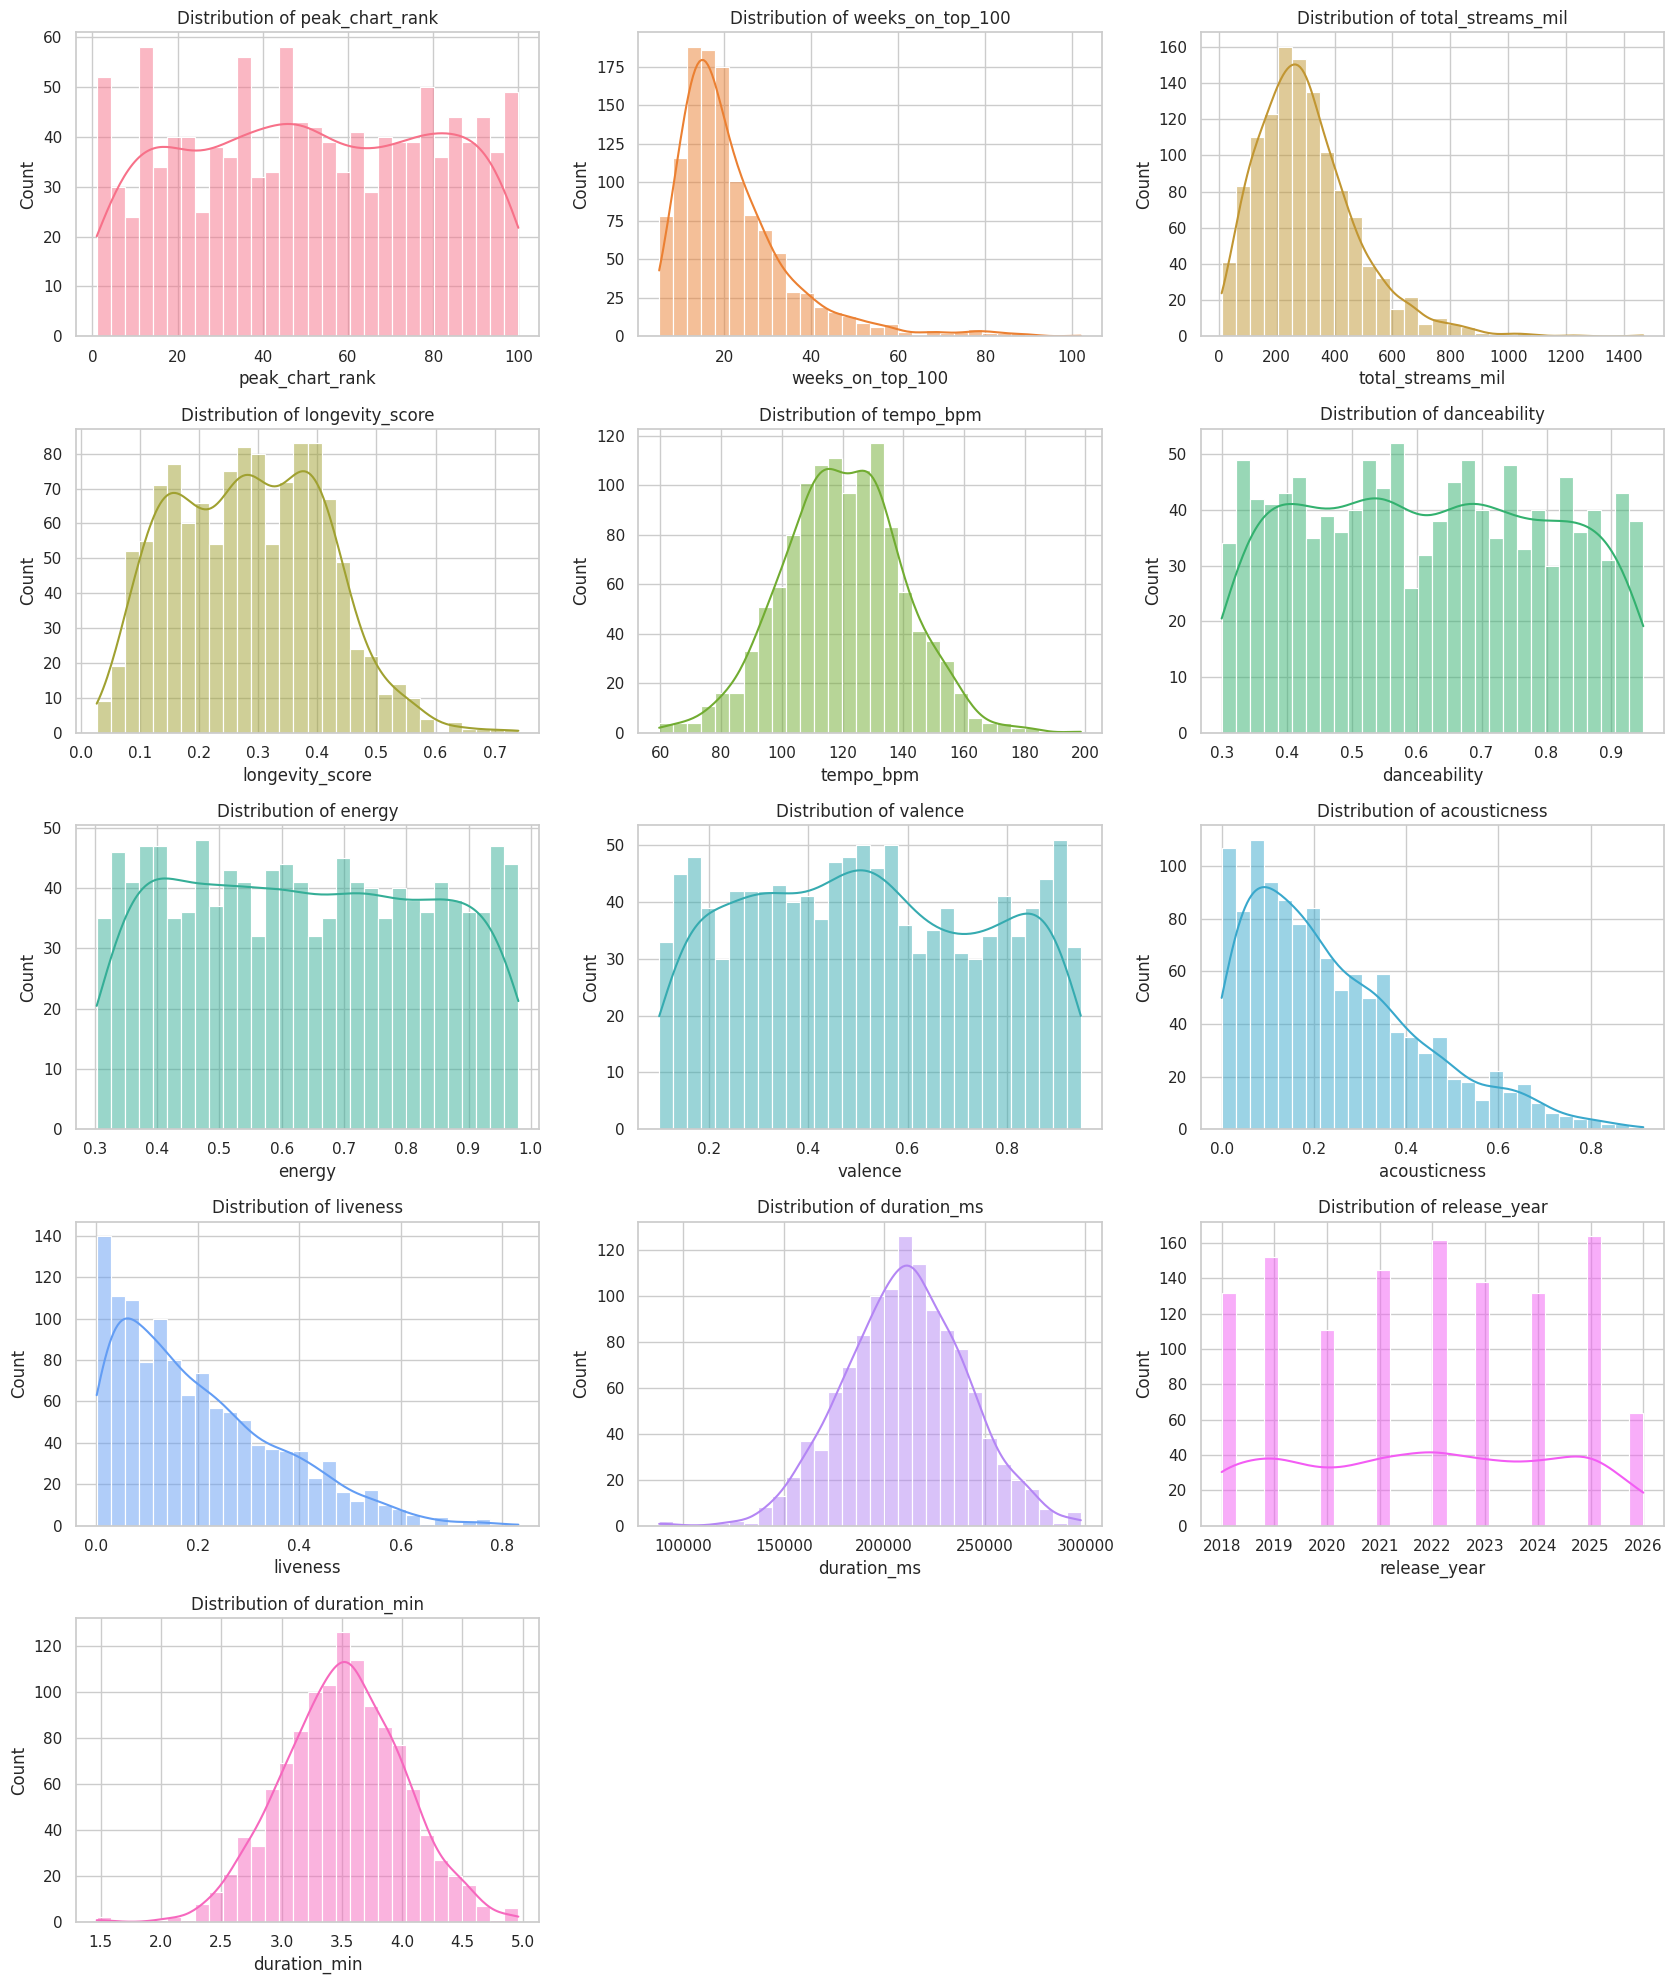

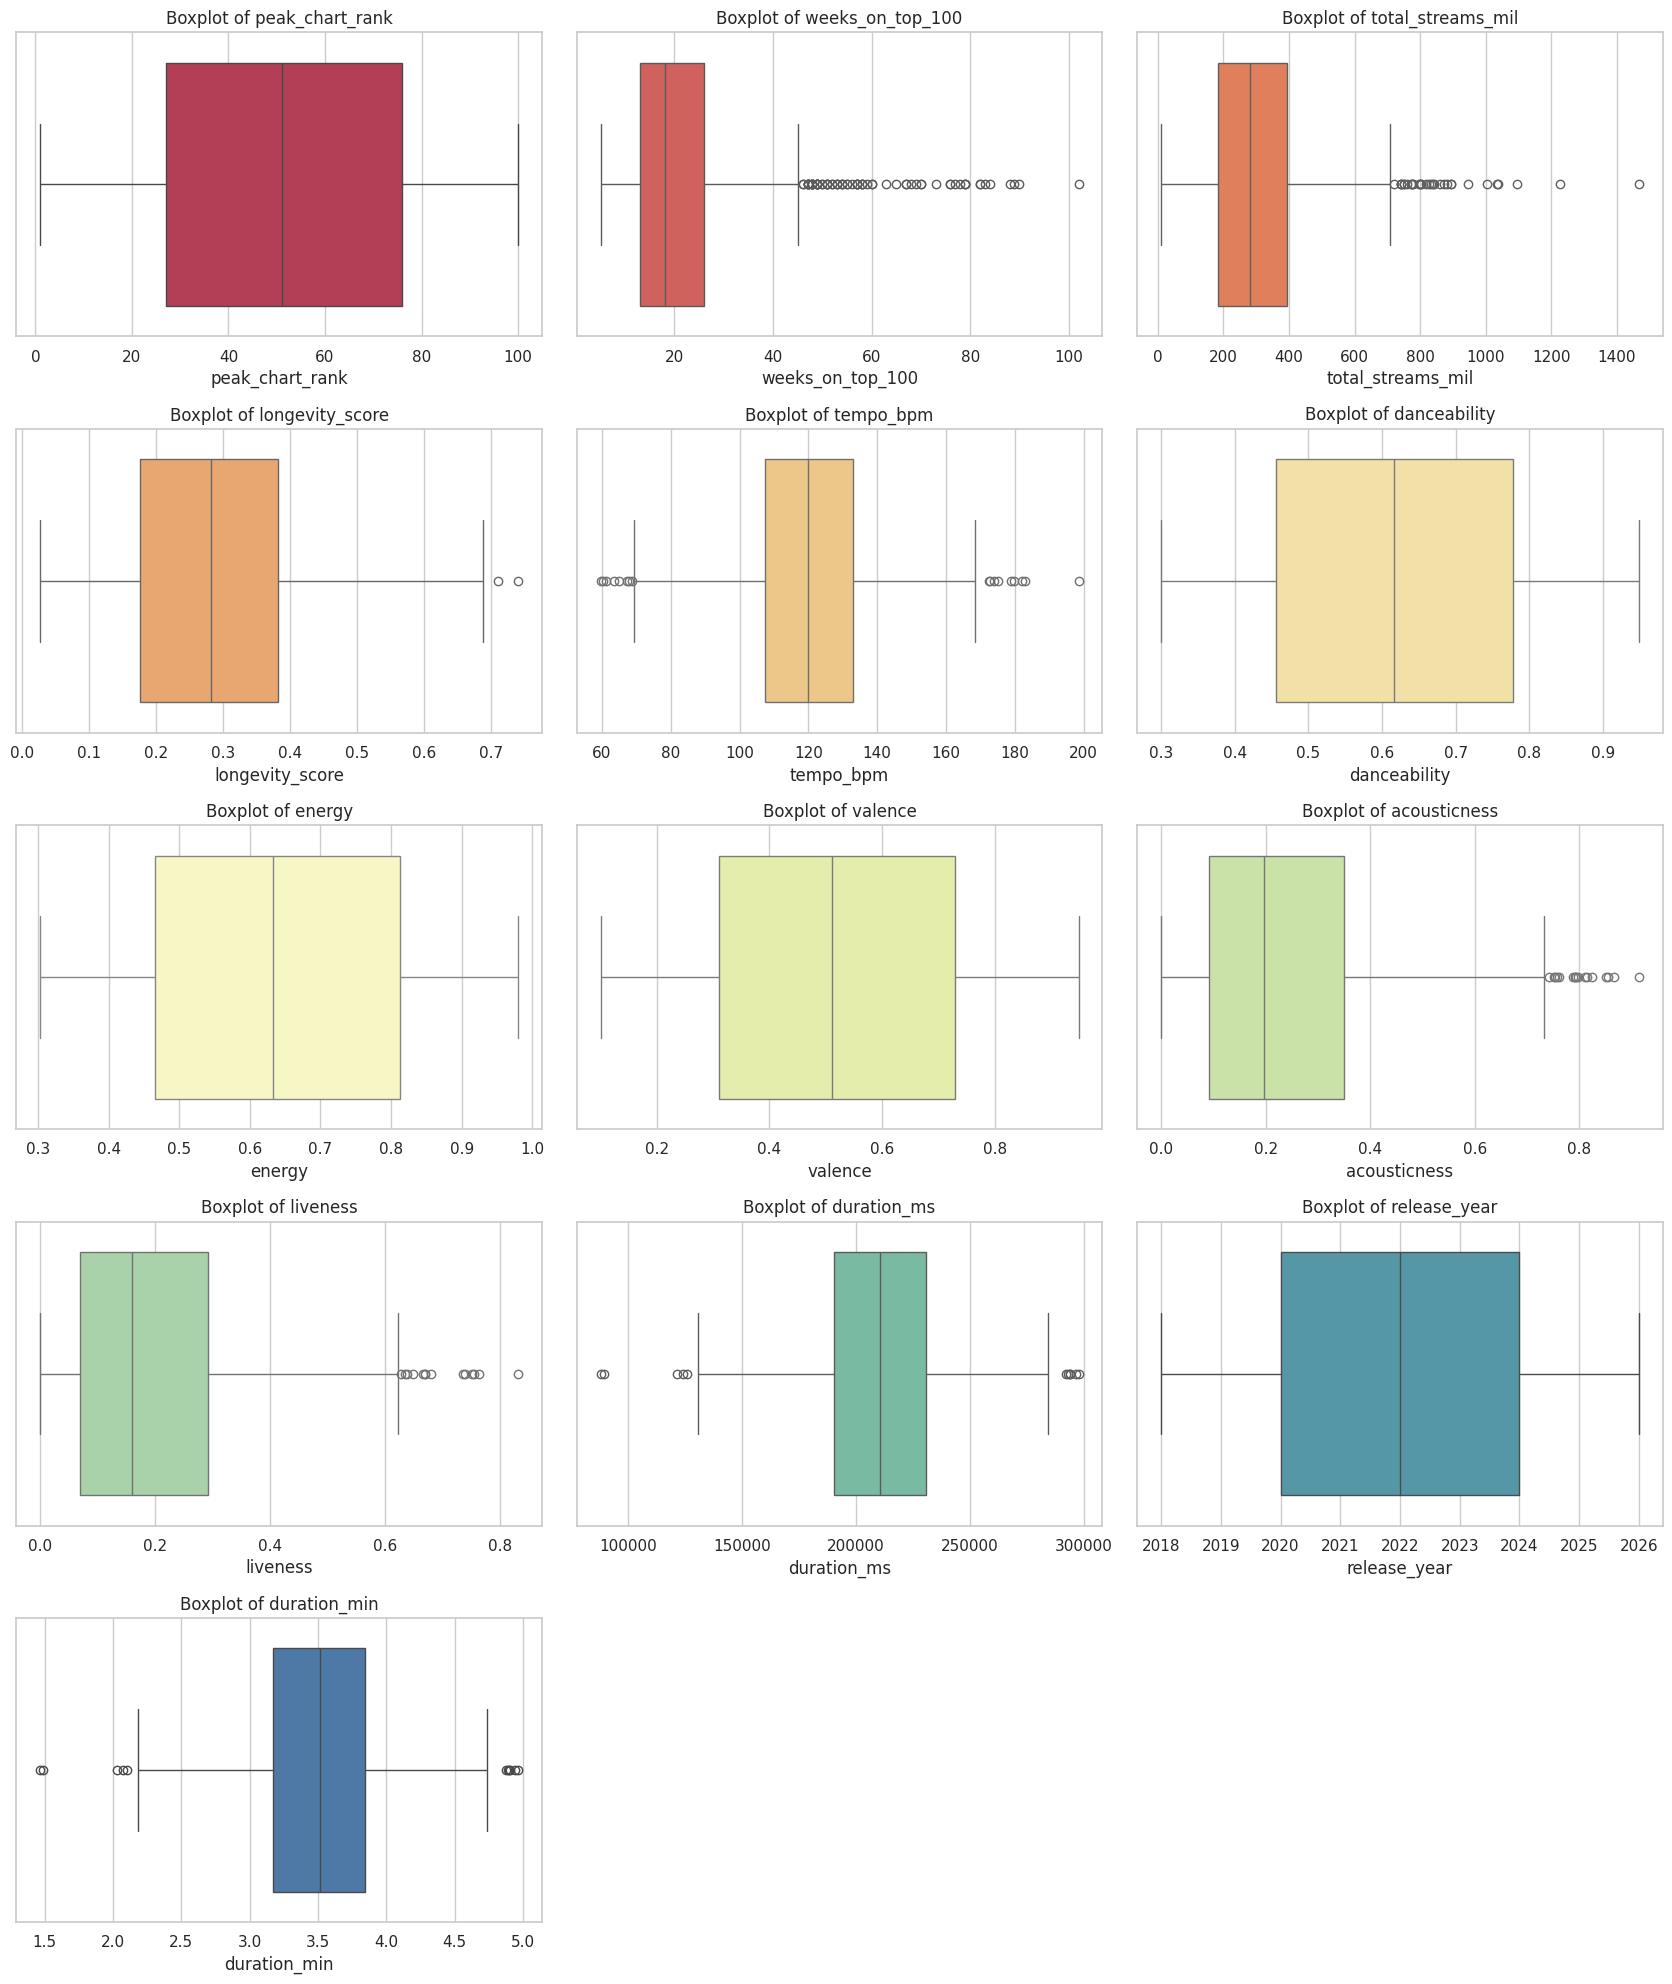

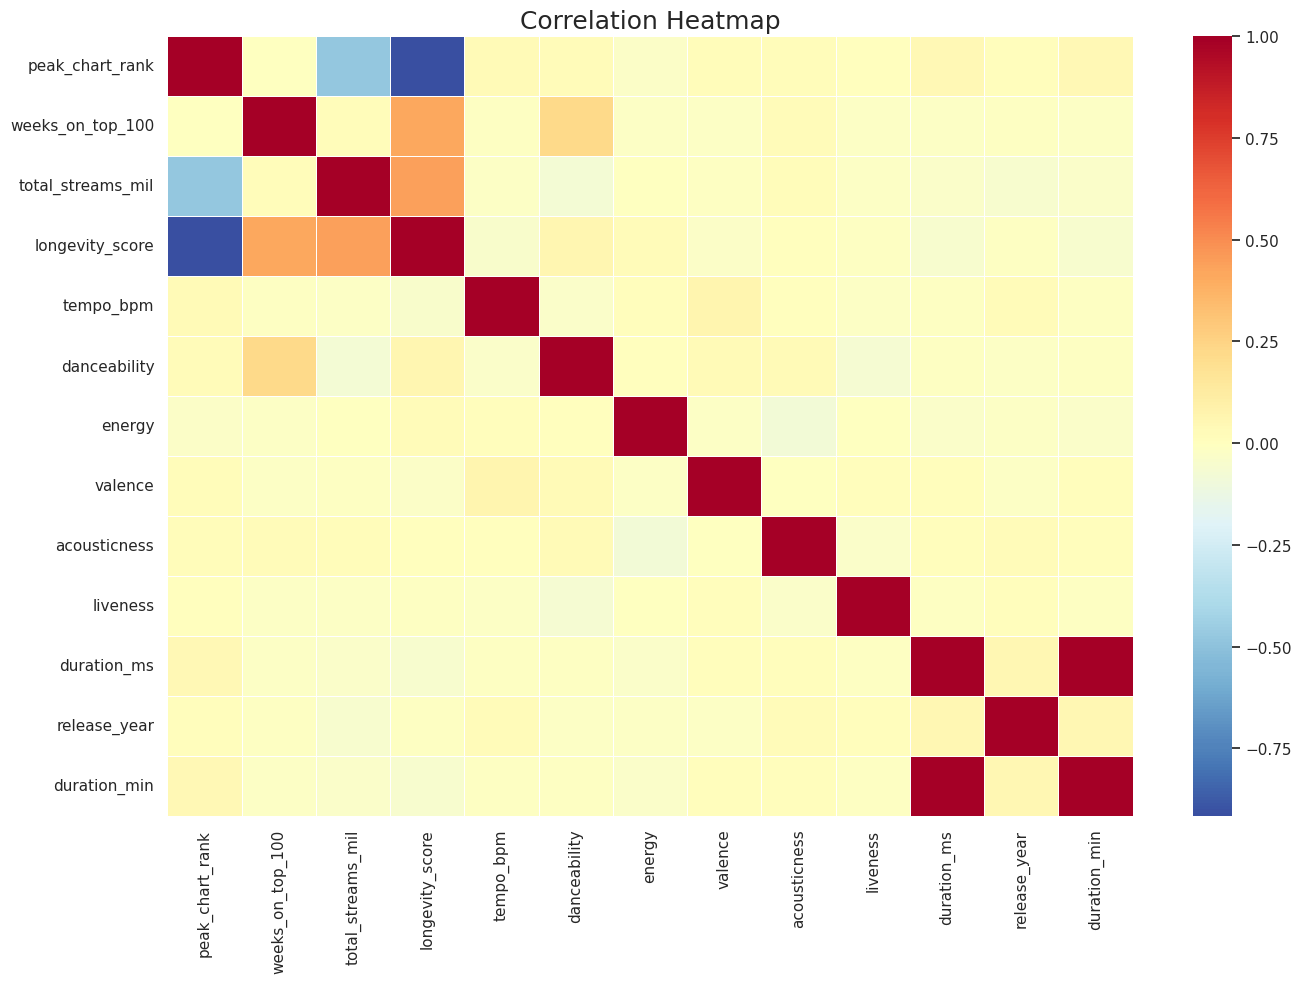

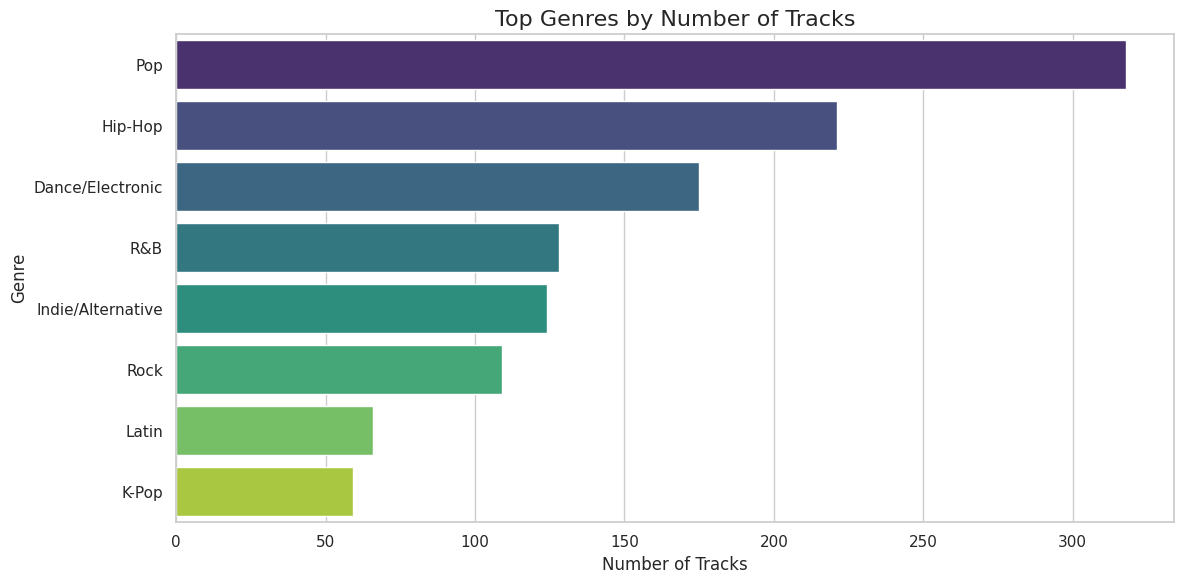

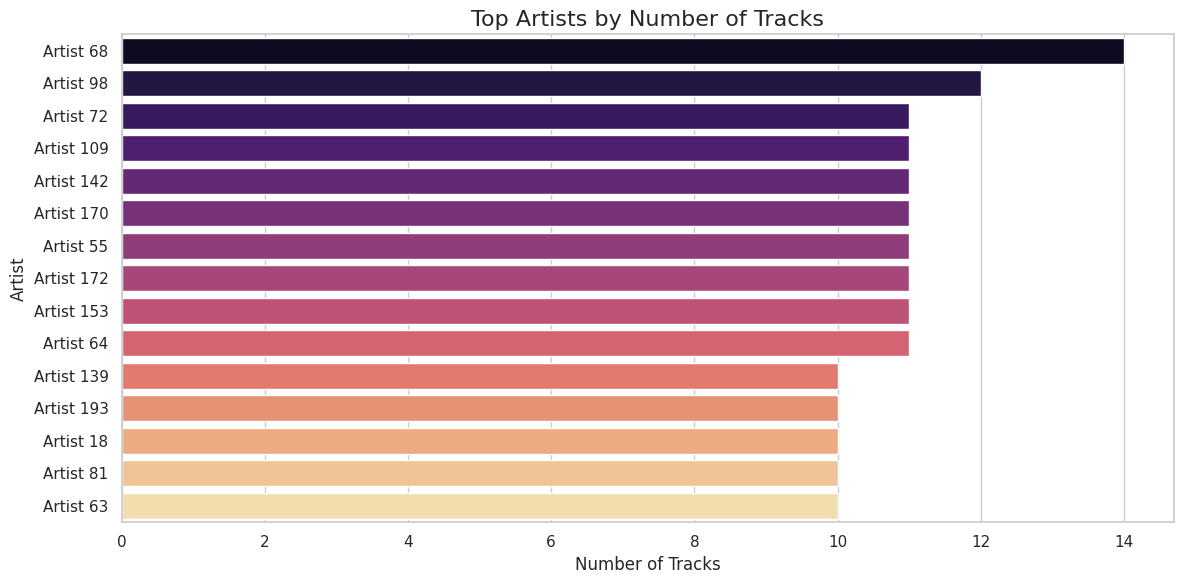

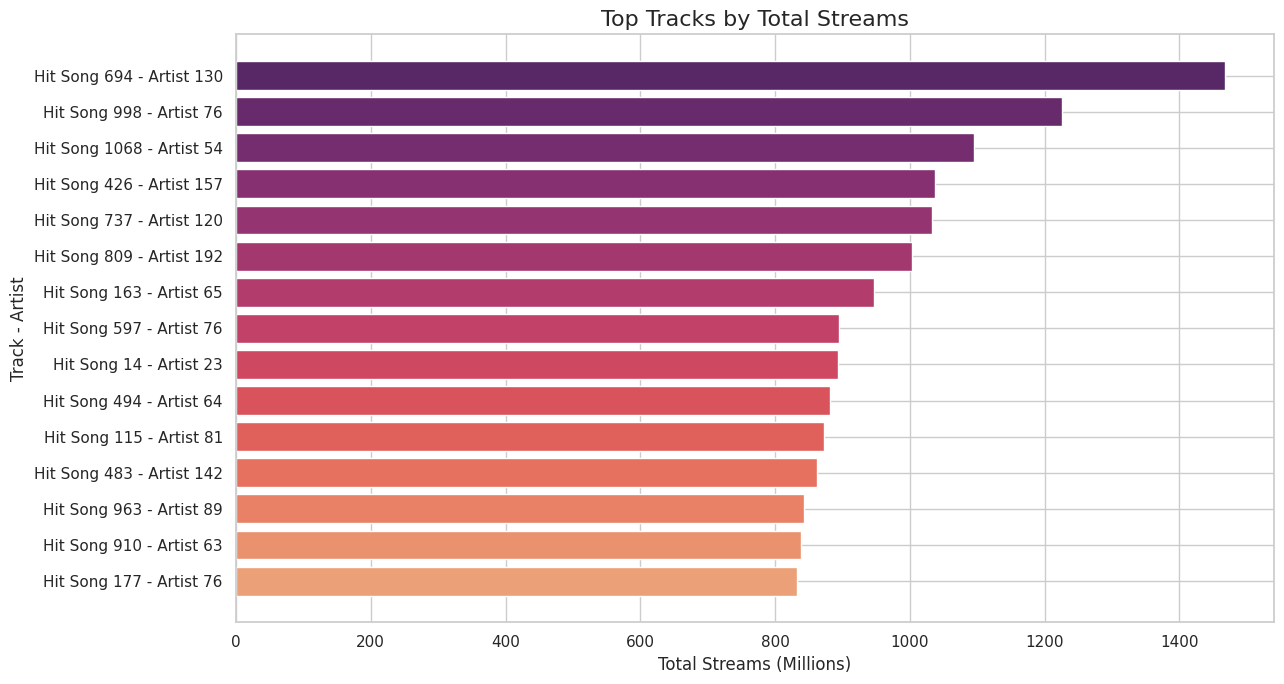

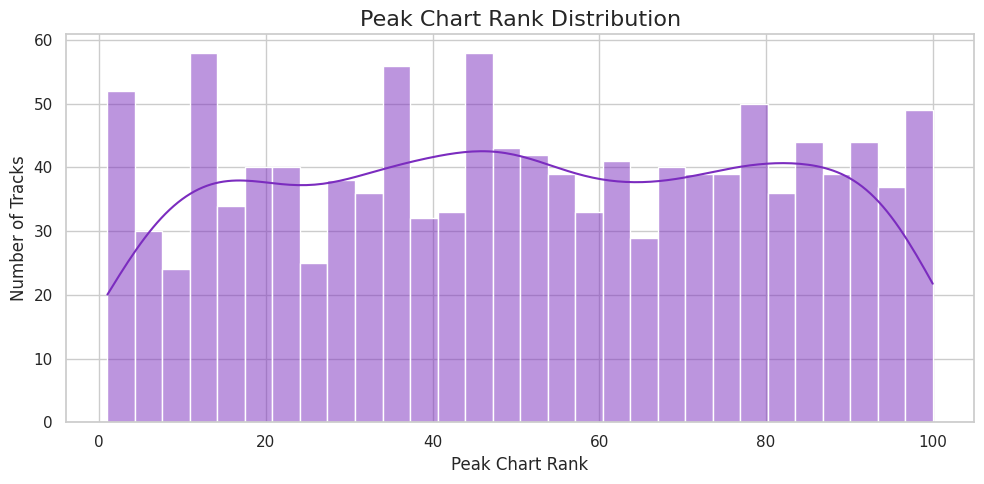

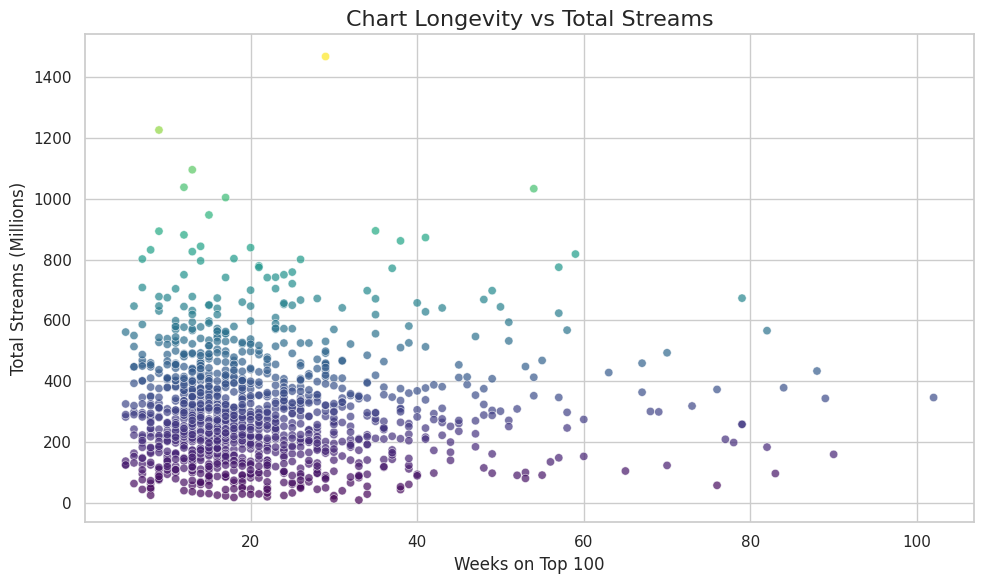

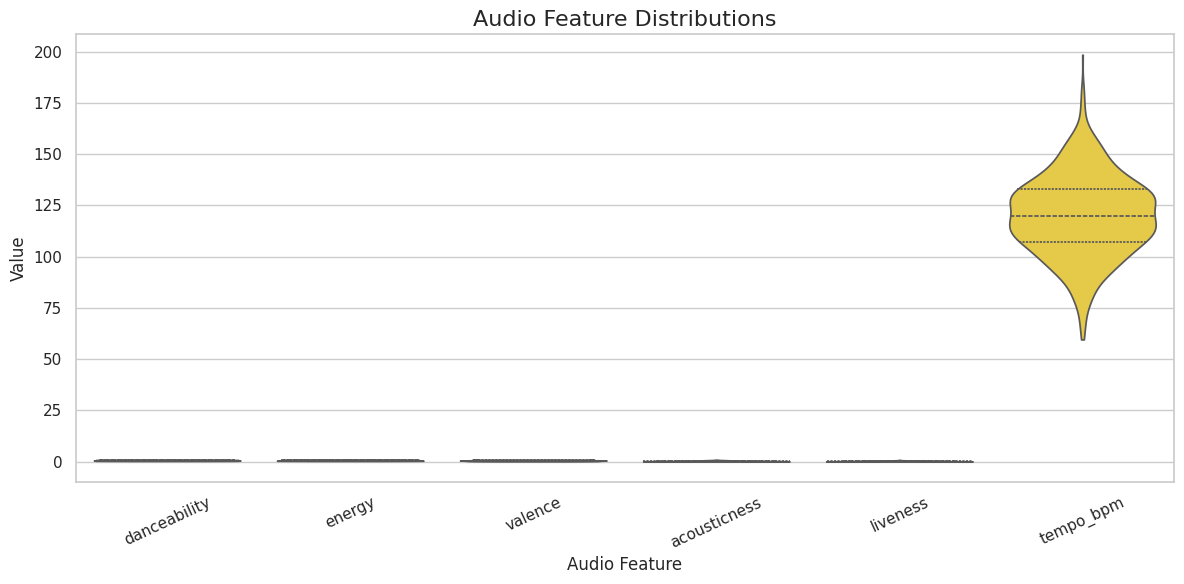

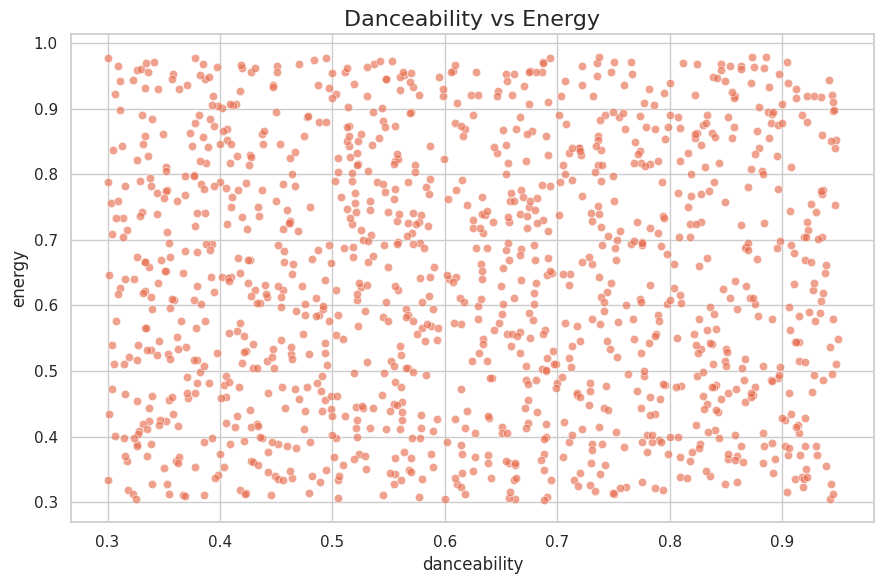

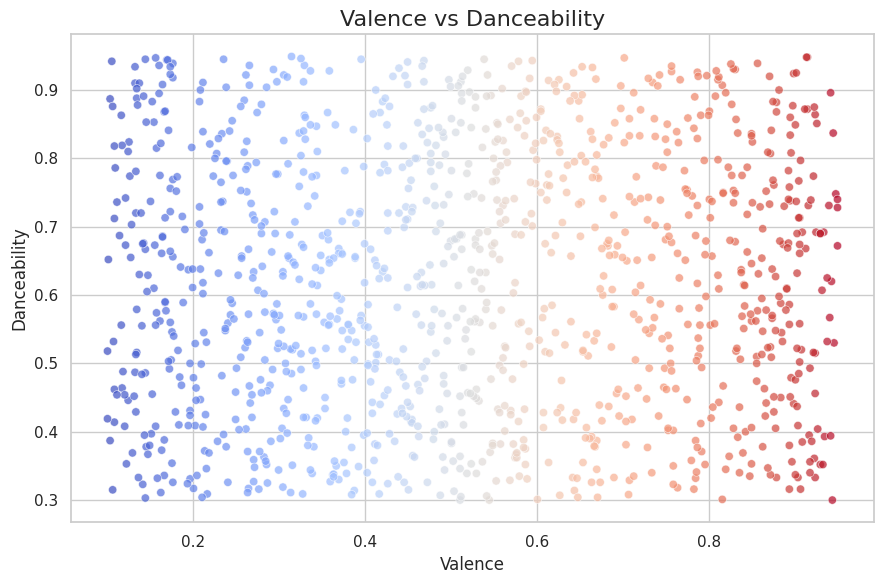

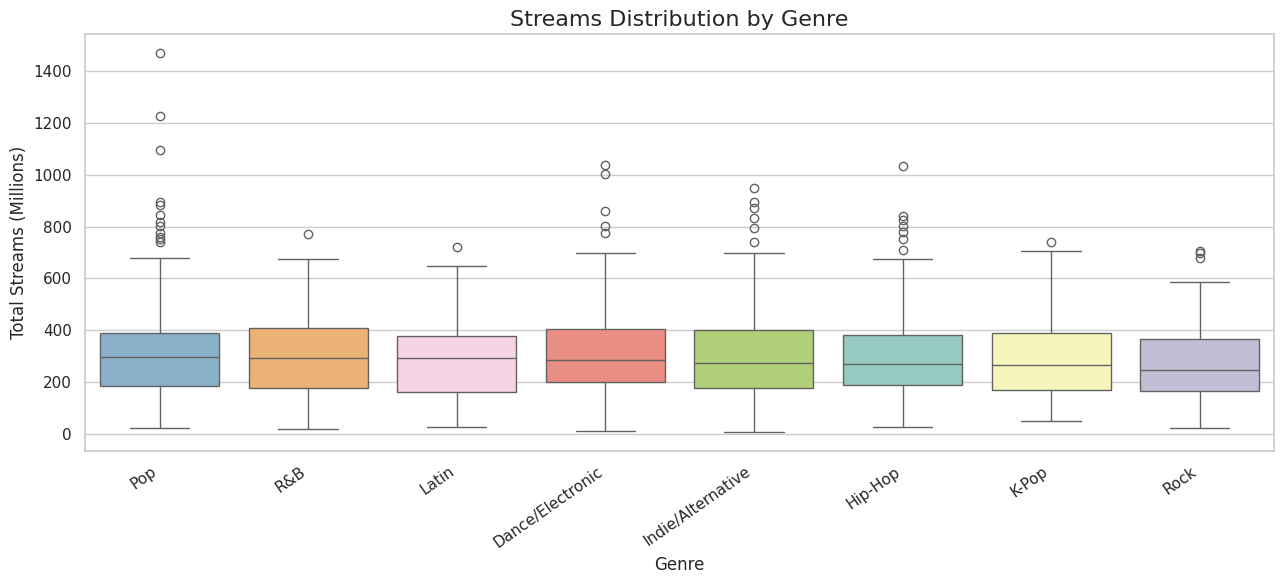

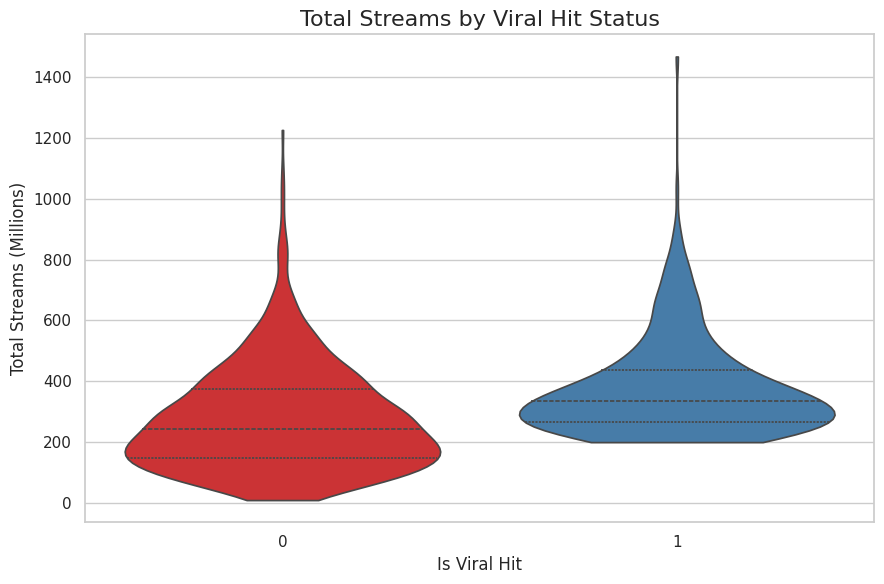

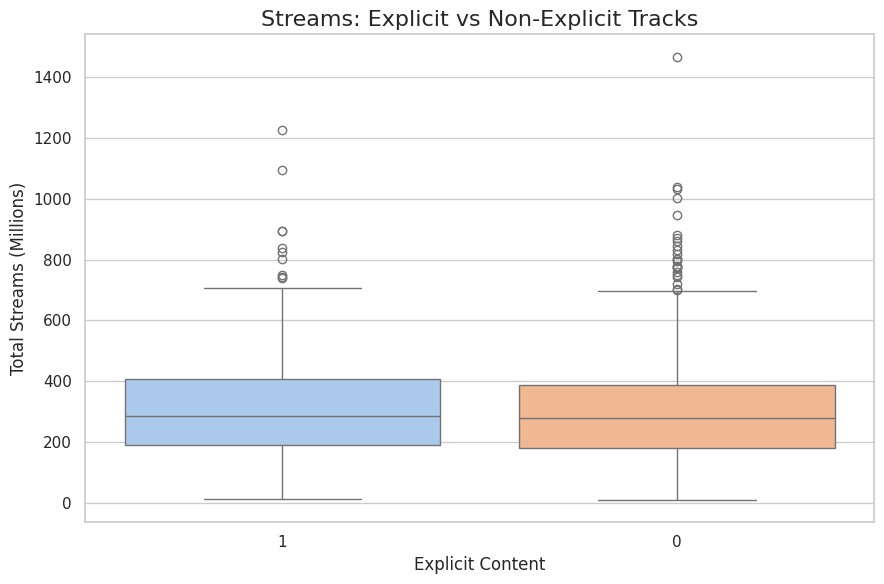

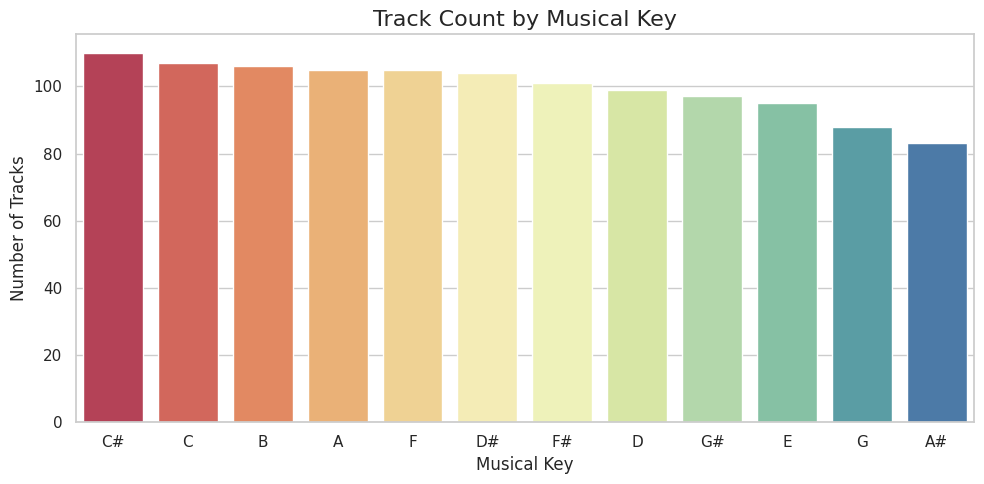

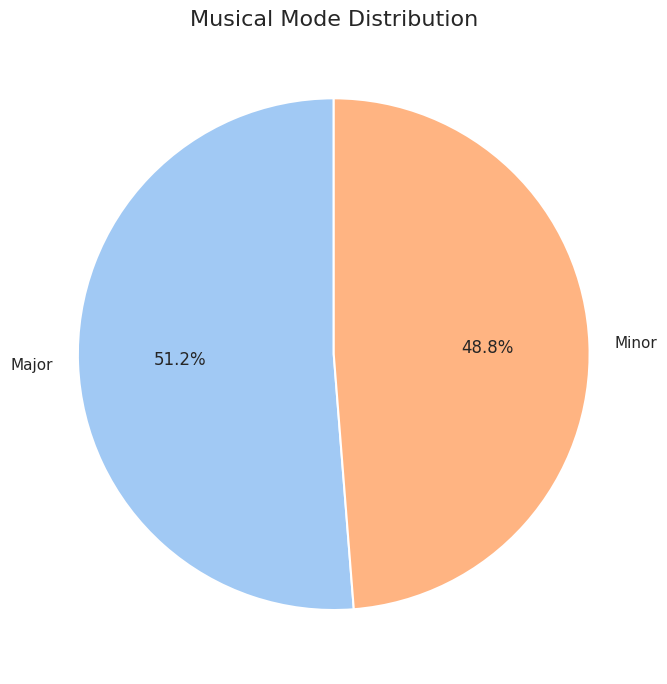

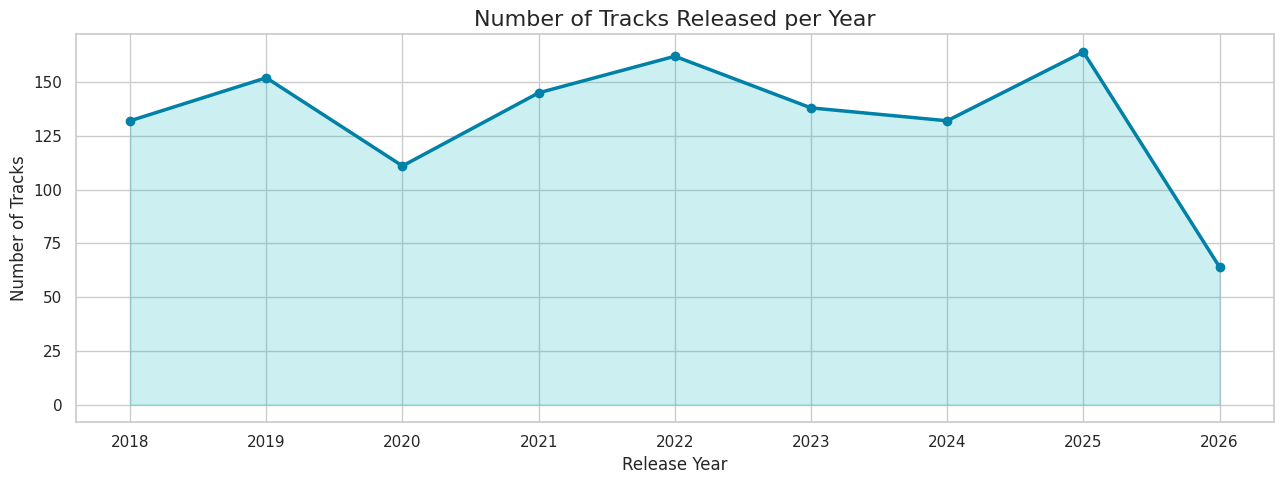

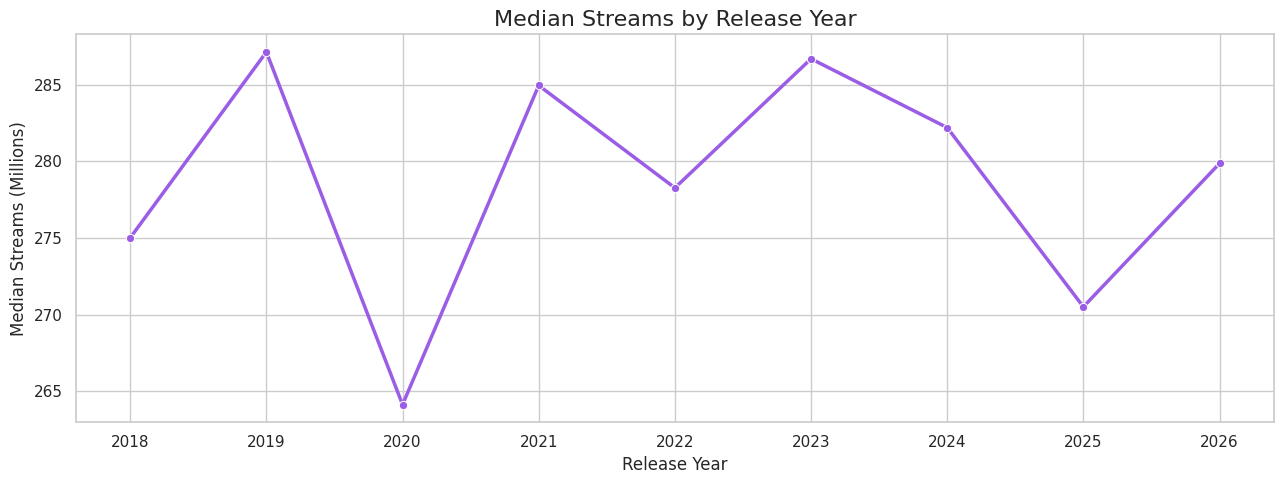

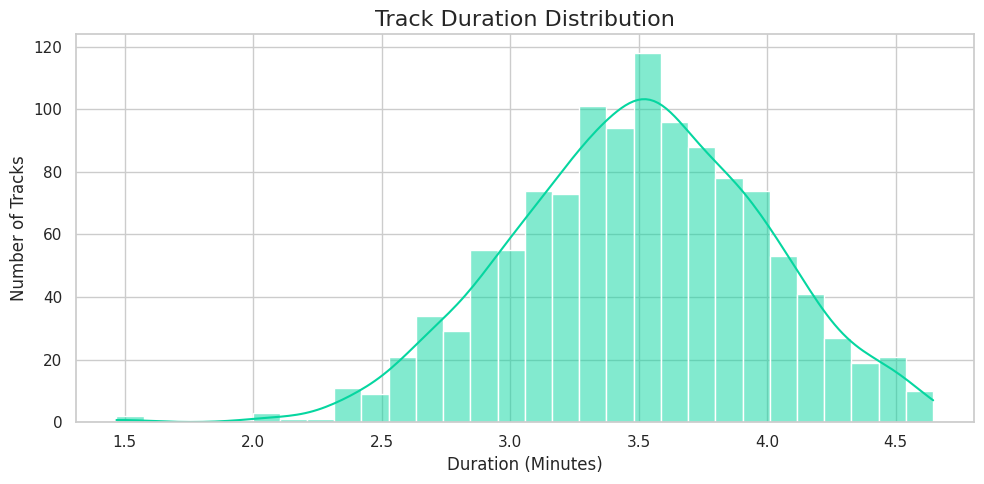

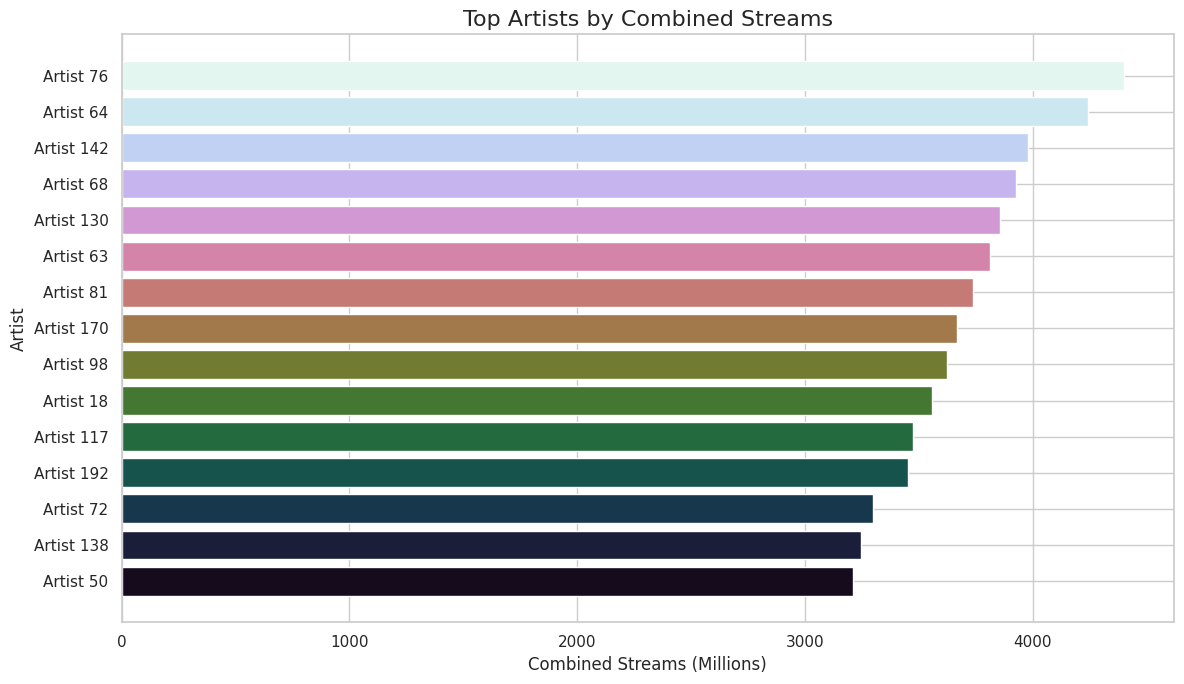

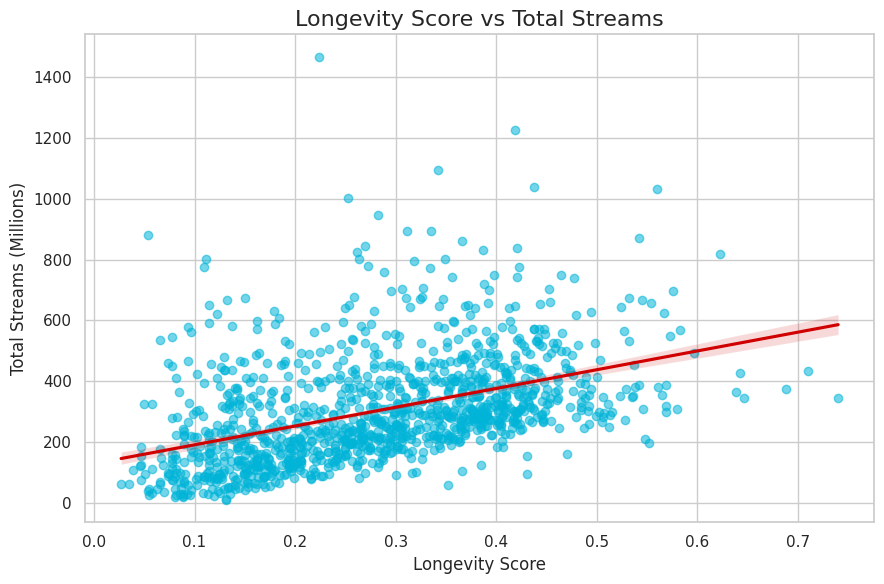

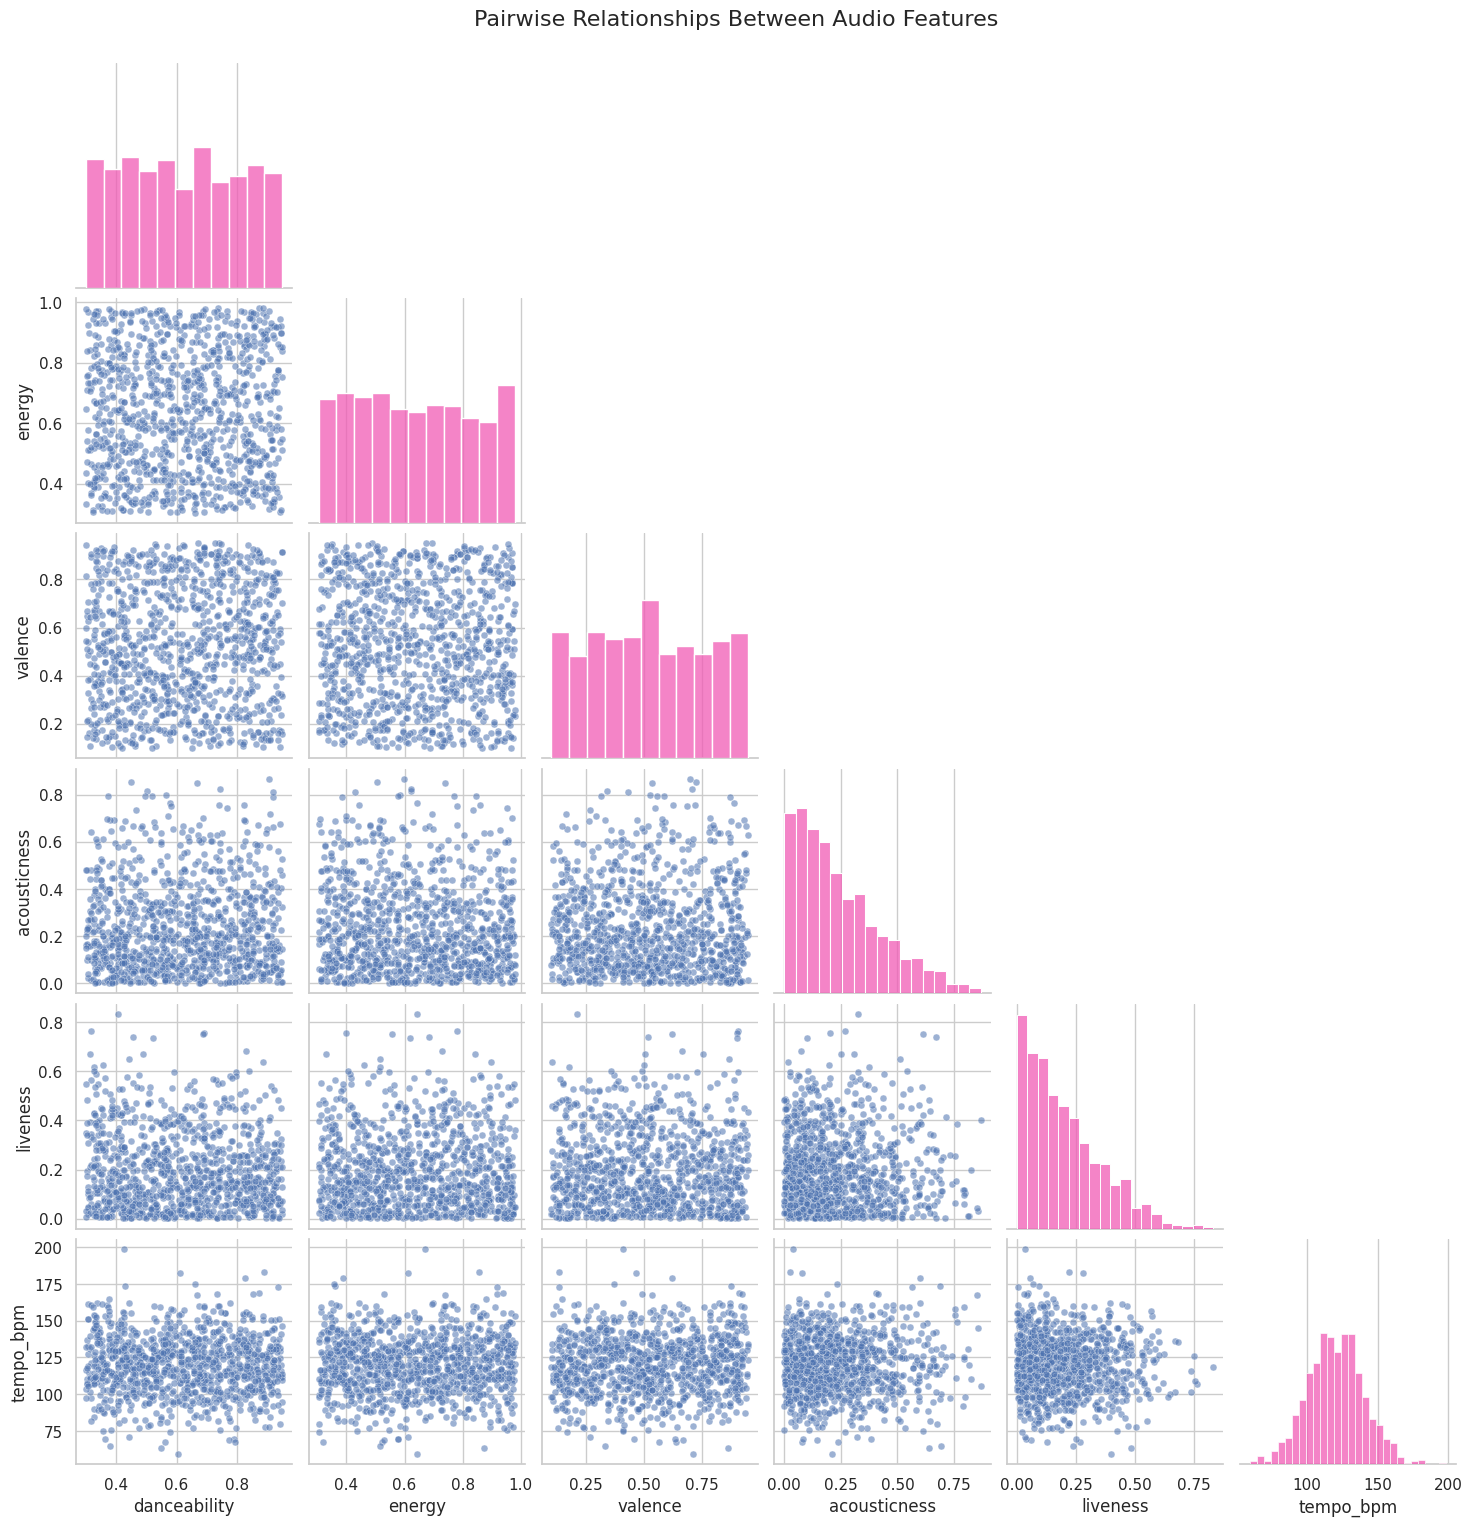

ALL MUSIC DATASET VISUALIZATIONS COMPLETED SUCCESSFULLY


In [15]:
# Visualization settings
sns.set_theme(style="whitegrid", context="notebook")
TOP_N = 15

# Use your existing merged dataset
data = df_merged.copy()
data.columns = data.columns.astype(str).str.strip()

# ------------------------------------------------------------
# 1. DATASET OVERVIEW
# ------------------------------------------------------------

print("=" * 70)
print("MUSIC STREAMING DATASET OVERVIEW")
print("=" * 70)

print("Dataset Shape:", data.shape)
print("\nFirst 5 Rows:")
display(data.head())

print("\nColumn Names:")
print(data.columns.tolist())

print("\nData Types:")
display(data.dtypes.astype(str).to_frame("Data Type"))

print("\nMissing Values:")
display(data.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\nDuplicate Rows:", data.duplicated().sum())

print("\nStatistical Summary:")
display(data.describe(include="all").T)

# ------------------------------------------------------------
# 2. DATA PREPARATION
# ------------------------------------------------------------

numeric_columns = [
    "peak_chart_rank", "weeks_on_top_100",
    "total_streams_mil", "longevity_score", "tempo_bpm",
    "danceability", "energy", "valence",
    "acousticness", "liveness", "duration_ms"
]

for col in numeric_columns:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

categorical_columns = [
    "is_viral_hit", "is_explicit", "mode",
    "musical_key", "genre", "artist_name", "track_title"
]

for col in categorical_columns:
    if col in data.columns:
        data[col] = data[col].astype("string").fillna("Unknown")

if "release_date" in data.columns:
    data["release_date"] = pd.to_datetime(
        data["release_date"], errors="coerce"
    )
    data["release_year"] = data["release_date"].dt.year

if "duration_ms" in data.columns:
    data["duration_min"] = data["duration_ms"] / 60000

# ------------------------------------------------------------
# 3. MISSING VALUES VISUALIZATION
# ------------------------------------------------------------

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette="rocket",
        legend=False
    )
    plt.title("Missing Values by Column", fontsize=16)
    plt.xlabel("Missing Values")
    plt.ylabel("Columns")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

# ------------------------------------------------------------
# 4. HISTOGRAMS FOR NUMERICAL FEATURES
# ------------------------------------------------------------

plot_numeric = [
    c for c in data.select_dtypes(include=np.number).columns
    if data[c].notna().any()
]

if plot_numeric:
    ncols = 3
    nrows = int(np.ceil(len(plot_numeric) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(17, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    colors = sns.color_palette("husl", len(plot_numeric))

    for i, col in enumerate(plot_numeric):
        sns.histplot(
            data[col].dropna(),
            bins=30,
            kde=data[col].nunique() > 5,
            color=colors[i],
            ax=axes[i]
        )
        axes[i].set_title(f"Distribution of {col}")
        axes[i].set_xlabel(col)

    for j in range(len(plot_numeric), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. BOXPLOTS FOR NUMERICAL FEATURES
# ------------------------------------------------------------

if plot_numeric:
    ncols = 3
    nrows = int(np.ceil(len(plot_numeric) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(17, 4 * nrows)
    )
    axes = np.array(axes).reshape(-1)

    colors = sns.color_palette("Spectral", len(plot_numeric))

    for i, col in enumerate(plot_numeric):
        sns.boxplot(
            x=data[col],
            color=colors[i],
            ax=axes[i]
        )
        axes[i].set_title(f"Boxplot of {col}")

    for j in range(len(plot_numeric), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. CORRELATION HEATMAP
# ------------------------------------------------------------

corr_columns = [
    c for c in plot_numeric
    if data[c].nunique(dropna=True) > 1
]

if len(corr_columns) >= 2:
    correlation = data[corr_columns].corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        correlation,
        annot=len(corr_columns) <= 12,
        fmt=".2f",
        cmap="RdYlBu_r",
        center=0,
        linewidths=0.5
    )
    plt.title("Correlation Heatmap", fontsize=18)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. TOP GENRES BY NUMBER OF TRACKS
# ------------------------------------------------------------

if "genre" in data.columns:
    genre_counts = data["genre"].value_counts().head(TOP_N)

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=genre_counts.values,
        y=genre_counts.index,
        hue=genre_counts.index,
        palette="viridis",
        legend=False
    )
    plt.title("Top Genres by Number of Tracks", fontsize=16)
    plt.xlabel("Number of Tracks")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. TOP ARTISTS BY NUMBER OF TRACKS
# ------------------------------------------------------------

if "artist_name" in data.columns:
    artist_counts = data["artist_name"].value_counts().head(TOP_N)

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=artist_counts.values,
        y=artist_counts.index,
        hue=artist_counts.index,
        palette="magma",
        legend=False
    )
    plt.title("Top Artists by Number of Tracks", fontsize=16)
    plt.xlabel("Number of Tracks")
    plt.ylabel("Artist")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 9. TOP TRACKS BY TOTAL STREAMS
# ------------------------------------------------------------

if {"track_title", "total_streams_mil"}.issubset(data.columns):
    top_tracks = data.nlargest(TOP_N, "total_streams_mil").copy()

    if not top_tracks.empty:
        top_tracks["track_label"] = top_tracks["track_title"].astype(str)

        if "artist_name" in top_tracks.columns:
            top_tracks["track_label"] += (
                " - " + top_tracks["artist_name"].astype(str)
            )

        top_tracks = top_tracks.sort_values("total_streams_mil")

        plt.figure(figsize=(13, 7))
        plt.barh(
            top_tracks["track_label"],
            top_tracks["total_streams_mil"],
            color=sns.color_palette("flare", len(top_tracks))
        )
        plt.title("Top Tracks by Total Streams", fontsize=16)
        plt.xlabel("Total Streams (Millions)")
        plt.ylabel("Track - Artist")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 10. PEAK CHART RANK DISTRIBUTION
# ------------------------------------------------------------

if "peak_chart_rank" in data.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(
        data["peak_chart_rank"].dropna(),
        bins=30,
        kde=True,
        color="#7B2CBF"
    )
    plt.title("Peak Chart Rank Distribution", fontsize=16)
    plt.xlabel("Peak Chart Rank")
    plt.ylabel("Number of Tracks")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 11. WEEKS ON TOP 100 VS TOTAL STREAMS
# ------------------------------------------------------------

if {"weeks_on_top_100", "total_streams_mil"}.issubset(data.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=data,
        x="weeks_on_top_100",
        y="total_streams_mil",
        hue="total_streams_mil",
        palette="viridis",
        alpha=0.7,
        legend=False
    )
    plt.title("Chart Longevity vs Total Streams", fontsize=16)
    plt.xlabel("Weeks on Top 100")
    plt.ylabel("Total Streams (Millions)")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. AUDIO FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

audio_features = [
    c for c in [
        "danceability", "energy", "valence",
        "acousticness", "liveness", "tempo_bpm"
    ] if c in data.columns
]

if audio_features:
    audio_data = data[audio_features].melt(
        var_name="Audio Feature",
        value_name="Value"
    ).dropna()

    plt.figure(figsize=(12, 6))
    sns.violinplot(
        data=audio_data,
        x="Audio Feature",
        y="Value",
        hue="Audio Feature",
        palette="Set2",
        legend=False,
        inner="quartile",
        cut=0
    )
    plt.title("Audio Feature Distributions", fontsize=16)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 13. DANCEABILITY VS ENERGY
# ------------------------------------------------------------

if {"danceability", "energy"}.issubset(data.columns):
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=data,
        x="danceability",
        y="energy",
        color="#E76F51",
        alpha=0.65
    )
    plt.title("Danceability vs Energy", fontsize=16)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 14. VALENCE VS DANCEABILITY
# ------------------------------------------------------------

if {"valence", "danceability"}.issubset(data.columns):
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=data,
        x="valence",
        y="danceability",
        hue="valence",
        palette="coolwarm",
        legend=False,
        alpha=0.7
    )
    plt.title("Valence vs Danceability", fontsize=16)
    plt.xlabel("Valence")
    plt.ylabel("Danceability")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 15. STREAMS BY GENRE
# ------------------------------------------------------------

if {"genre", "total_streams_mil"}.issubset(data.columns):
    top_genres = data["genre"].value_counts().head(10).index

    genre_data = data[
        data["genre"].isin(top_genres)
    ].dropna(subset=["total_streams_mil"])

    if not genre_data.empty:
        order = (
            genre_data.groupby("genre")["total_streams_mil"]
            .median()
            .sort_values(ascending=False)
            .index
        )

        plt.figure(figsize=(13, 6))
        sns.boxplot(
            data=genre_data,
            x="genre",
            y="total_streams_mil",
            order=order,
            hue="genre",
            palette="Set3",
            legend=False
        )
        plt.title("Streams Distribution by Genre", fontsize=16)
        plt.xlabel("Genre")
        plt.ylabel("Total Streams (Millions)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 16. STREAMS BY VIRAL HIT STATUS
# ------------------------------------------------------------

if {"is_viral_hit", "total_streams_mil"}.issubset(data.columns):
    plt.figure(figsize=(9, 6))
    sns.violinplot(
        data=data.dropna(subset=["total_streams_mil"]),
        x="is_viral_hit",
        y="total_streams_mil",
        hue="is_viral_hit",
        palette="Set1",
        legend=False,
        inner="quartile",
        cut=0
    )
    plt.title("Total Streams by Viral Hit Status", fontsize=16)
    plt.xlabel("Is Viral Hit")
    plt.ylabel("Total Streams (Millions)")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 17. EXPLICIT VS NON-EXPLICIT STREAMS
# ------------------------------------------------------------

if {"is_explicit", "total_streams_mil"}.issubset(data.columns):
    plt.figure(figsize=(9, 6))
    sns.boxplot(
        data=data.dropna(subset=["total_streams_mil"]),
        x="is_explicit",
        y="total_streams_mil",
        hue="is_explicit",
        palette="pastel",
        legend=False
    )
    plt.title("Streams: Explicit vs Non-Explicit Tracks", fontsize=16)
    plt.xlabel("Explicit Content")
    plt.ylabel("Total Streams (Millions)")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 18. MUSICAL KEY DISTRIBUTION
# ------------------------------------------------------------

if "musical_key" in data.columns:
    key_counts = data["musical_key"].value_counts().head(15)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=key_counts.index.astype(str),
        y=key_counts.values,
        hue=key_counts.index.astype(str),
        palette="Spectral",
        legend=False
    )
    plt.title("Track Count by Musical Key", fontsize=16)
    plt.xlabel("Musical Key")
    plt.ylabel("Number of Tracks")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 19. MUSICAL MODE DISTRIBUTION
# ------------------------------------------------------------

if "mode" in data.columns:
    mode_counts = data["mode"].value_counts()

    plt.figure(figsize=(7, 7))
    plt.pie(
        mode_counts.values,
        labels=mode_counts.index.astype(str),
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("pastel", len(mode_counts)),
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}
    )
    plt.title("Musical Mode Distribution", fontsize=16)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 20. TRACK RELEASES PER YEAR
# ------------------------------------------------------------

if "release_year" in data.columns:
    year_counts = (
        data["release_year"]
        .dropna()
        .astype(int)
        .value_counts()
        .sort_index()
    )

    if not year_counts.empty:
        plt.figure(figsize=(13, 5))
        plt.plot(
            year_counts.index,
            year_counts.values,
            marker="o",
            linewidth=2.5,
            color="#0081A7"
        )
        plt.fill_between(
            year_counts.index,
            year_counts.values,
            alpha=0.2,
            color="#00AFB9"
        )
        plt.title("Number of Tracks Released per Year", fontsize=16)
        plt.xlabel("Release Year")
        plt.ylabel("Number of Tracks")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 21. MEDIAN STREAMS BY RELEASE YEAR
# ------------------------------------------------------------

if {"release_year", "total_streams_mil"}.issubset(data.columns):
    yearly_streams = (
        data.dropna(subset=["release_year", "total_streams_mil"])
        .groupby("release_year")["total_streams_mil"]
        .median()
        .reset_index()
    )

    if not yearly_streams.empty:
        plt.figure(figsize=(13, 5))
        sns.lineplot(
            data=yearly_streams,
            x="release_year",
            y="total_streams_mil",
            marker="o",
            color="#9B5DE5",
            linewidth=2.5
        )
        plt.title("Median Streams by Release Year", fontsize=16)
        plt.xlabel("Release Year")
        plt.ylabel("Median Streams (Millions)")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 22. TRACK DURATION DISTRIBUTION
# ------------------------------------------------------------

if "duration_min" in data.columns:
    durations = data["duration_min"].dropna()
    durations = durations[durations > 0]

    if not durations.empty:
        durations = durations[
            durations <= durations.quantile(0.99)
        ]

        plt.figure(figsize=(10, 5))
        sns.histplot(
            durations,
            bins=30,
            kde=True,
            color="#06D6A0"
        )
        plt.title("Track Duration Distribution", fontsize=16)
        plt.xlabel("Duration (Minutes)")
        plt.ylabel("Number of Tracks")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 23. TOP ARTISTS BY COMBINED STREAMS
# ------------------------------------------------------------

if {"artist_name", "total_streams_mil"}.issubset(data.columns):
    artist_streams = (
        data.dropna(subset=["total_streams_mil"])
        .groupby("artist_name")["total_streams_mil"]
        .sum()
        .nlargest(TOP_N)
        .sort_values()
    )

    if not artist_streams.empty:
        plt.figure(figsize=(12, 7))
        plt.barh(
            artist_streams.index.astype(str),
            artist_streams.values,
            color=sns.color_palette("cubehelix", len(artist_streams))
        )
        plt.title("Top Artists by Combined Streams", fontsize=16)
        plt.xlabel("Combined Streams (Millions)")
        plt.ylabel("Artist")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 24. LONGEVITY SCORE VS STREAMS
# ------------------------------------------------------------

if {"longevity_score", "total_streams_mil"}.issubset(data.columns):
    plot_data = data[
        ["longevity_score", "total_streams_mil"]
    ].dropna()

    if len(plot_data) > 1:
        plt.figure(figsize=(9, 6))
        sns.regplot(
            data=plot_data,
            x="longevity_score",
            y="total_streams_mil",
            scatter_kws={"alpha": 0.55, "color": "#00B4D8"},
            line_kws={"color": "#D00000"}
        )
        plt.title("Longevity Score vs Total Streams", fontsize=16)
        plt.xlabel("Longevity Score")
        plt.ylabel("Total Streams (Millions)")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 25. PAIRPLOT OF AUDIO FEATURES
# ------------------------------------------------------------

pair_columns = [
    c for c in [
        "danceability", "energy", "valence",
        "acousticness", "liveness", "tempo_bpm"
    ]
    if c in data.columns and data[c].notna().sum() > 1
]

if len(pair_columns) >= 2:
    pair_data = data[pair_columns].dropna()

    if len(pair_data) > 1000:
        pair_data = pair_data.sample(
            1000, random_state=42
        )

    if len(pair_data) > 1:
        pair_plot = sns.pairplot(
            pair_data,
            diag_kind="hist",
            corner=True,
            plot_kws={"alpha": 0.55, "s": 25},
            diag_kws={"color": "#F15BB5"}
        )
        pair_plot.fig.suptitle(
            "Pairwise Relationships Between Audio Features",
            y=1.02,
            fontsize=16
        )
        plt.show()

print("=" * 70)
print("ALL MUSIC DATASET VISUALIZATIONS COMPLETED SUCCESSFULLY")
print("=" * 70)


## Feature engineering

MUSIC STREAMING MACHINE LEARNING
Original dataset shape: (1200, 20)

Target distribution:


,Count
is_viral_hit,
no,856
yes,344



Target class percentages:


,Percentage
is_viral_hit,
no,71.33
yes,28.67



Target label encoding:
no -> 0
yes -> 1

Positive class for ROC: yes

Selected feature count: 14
Numeric features: ['tempo_bpm', 'danceability', 'energy', 'valence', 'acousticness', 'liveness', 'duration_ms', 'release_year', 'release_month', 'duration_min']
Categorical features: ['musical_key', 'mode', 'genre', 'is_explicit']
Excluded columns: ['is_viral_hit', 'track_id', 'track_title', 'artist_name', 'release_date', 'total_streams_mil', 'weeks_on_top_100', 'longevity_score', 'peak_chart_rank']

Feature preview:


...

is_viral_hit
0    71.35
1    28.65
Name: proportion, dtype: float64


Testing target distribution (%):


is_viral_hit
0    71.25
1    28.75
Name: proportion, dtype: float64


TRAINING: Logistic Regression
Accuracy:  50.00%
Precision: 27.03%
Recall:    43.48%
F1 Score:  33.33%
ROC AUC:   48.67%

Classification Report:
              precision    recall  f1-score   support

          no       0.70      0.53      0.60       171
         yes       0.27      0.43      0.33        69

    accuracy                           0.50       240
   macro avg       0.48      0.48      0.47       240
weighted avg       0.57      0.50      0.52       240


TRAINING: Decision Tree
Accuracy:  57.50%
Precision: 31.87%
Recall:    42.03%
F1 Score:  36.25%
ROC AUC:   50.75%

Classification Report:
              precision    recall  f1-score   support

          no       0.73      0.64      0.68       171
         yes       0.32      0.42      0.36        69

    accuracy                           0.57       240
   macro avg       0.53      0.53      0.52       240
weighted avg       0.61      0.57      0.59       240


TRAINING: Random Forest
Accuracy:  68.33%
Precision: 26.67%
R

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC AUC (%)
0,Gradient Boosting,67.92,27.78,7.25,11.49,54.59
1,Decision Tree,57.50,31.87,42.03,36.25,50.75
2,Random Forest,68.33,26.67,5.80,9.52,48.67
3,Logistic Regression,50.00,27.03,43.48,33.33,48.67
4,Extra Trees,61.67,24.44,15.94,19.30,48.50
5,K-Nearest Neighbors,64.58,16.67,5.80,8.60,46.80


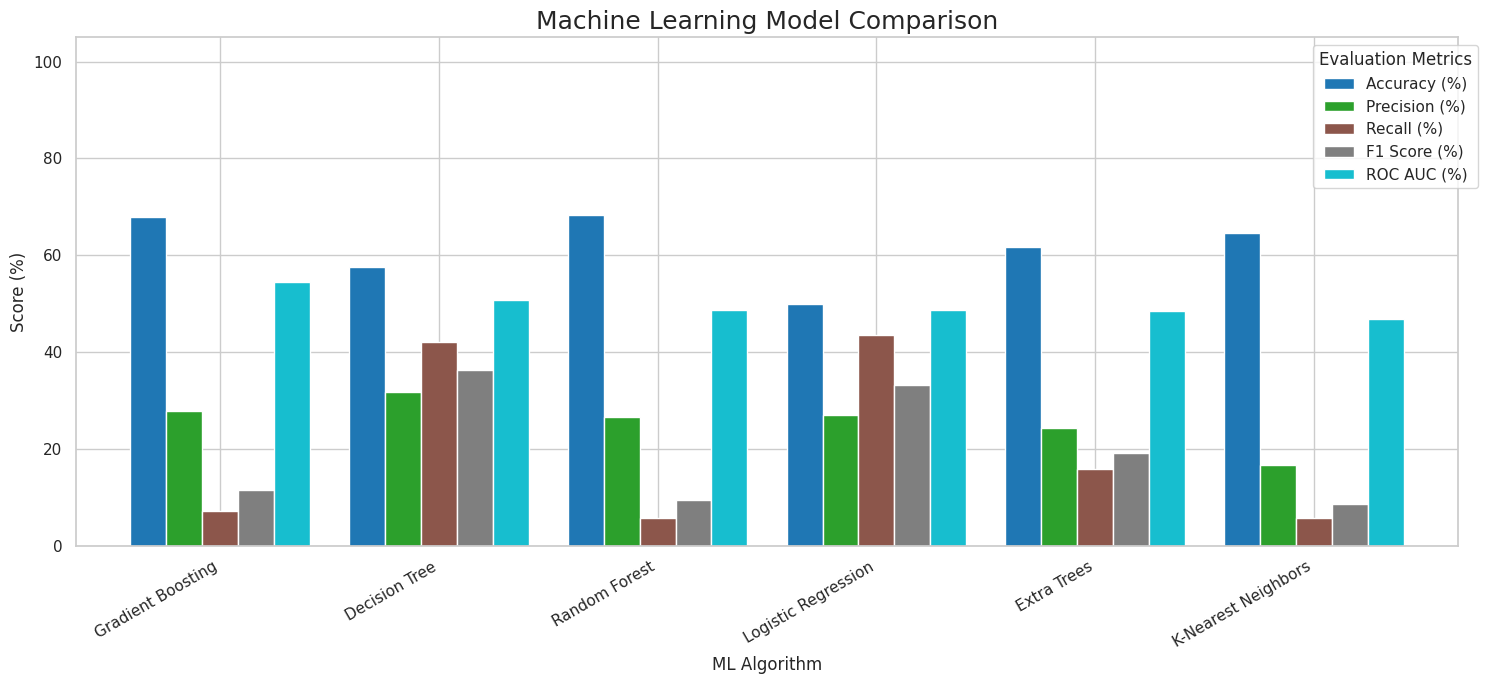

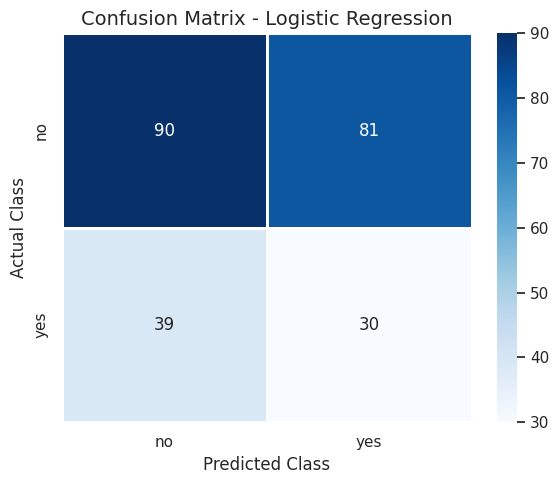

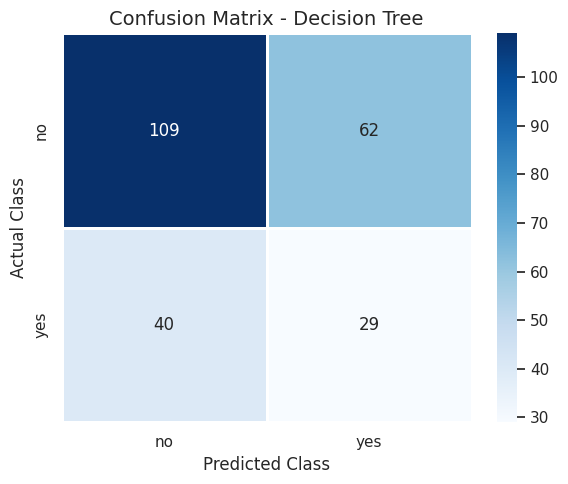

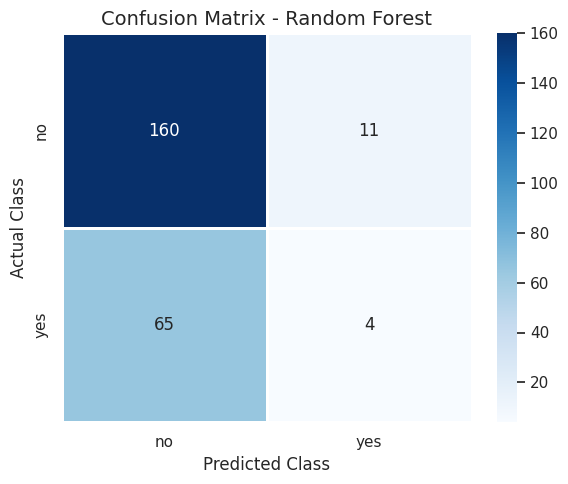

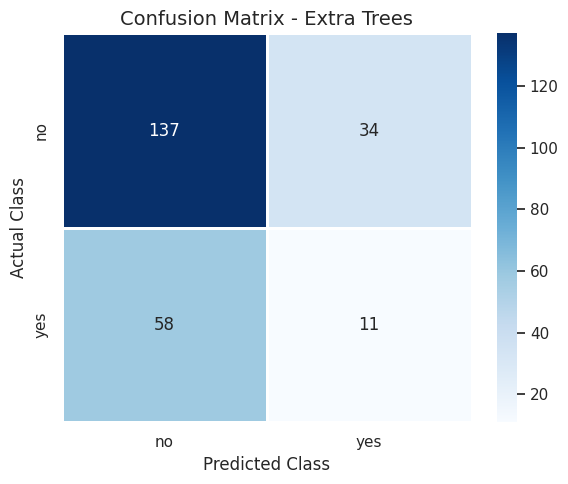

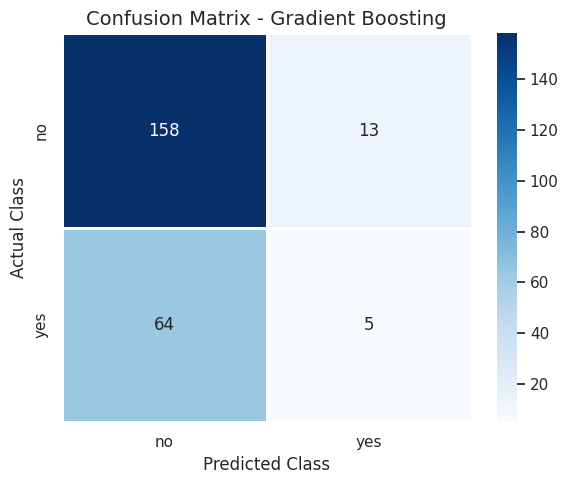

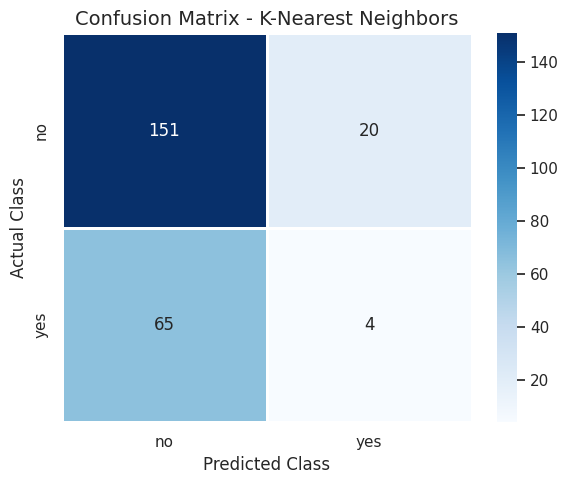

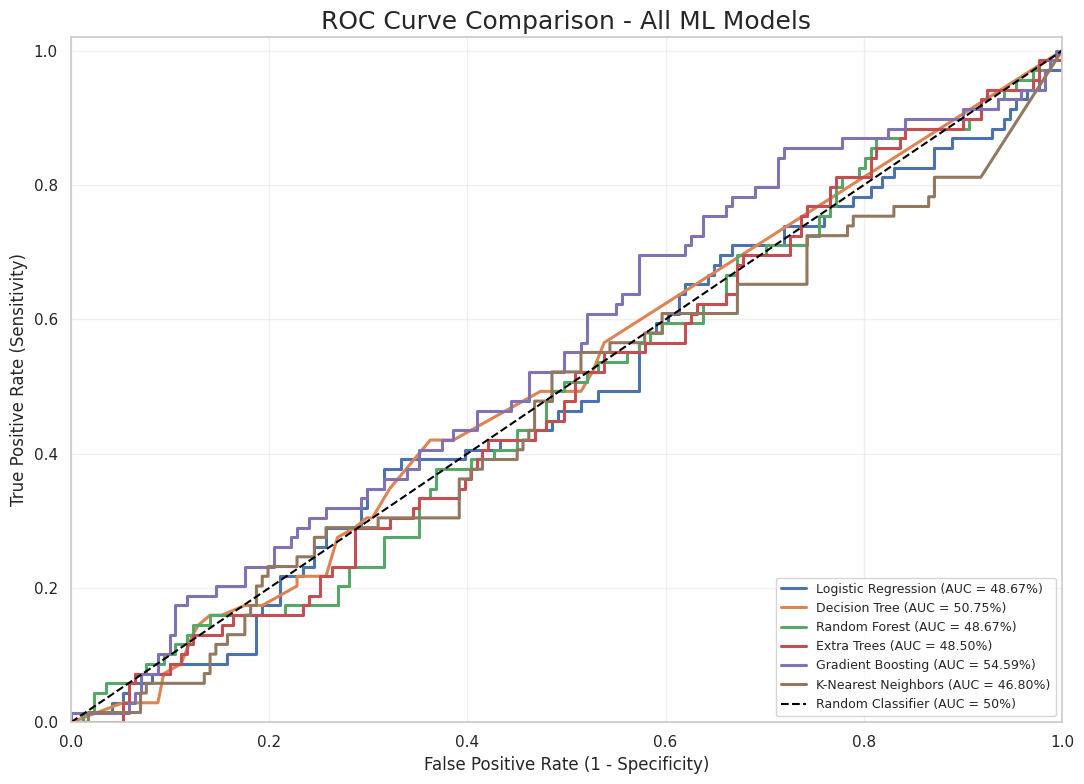

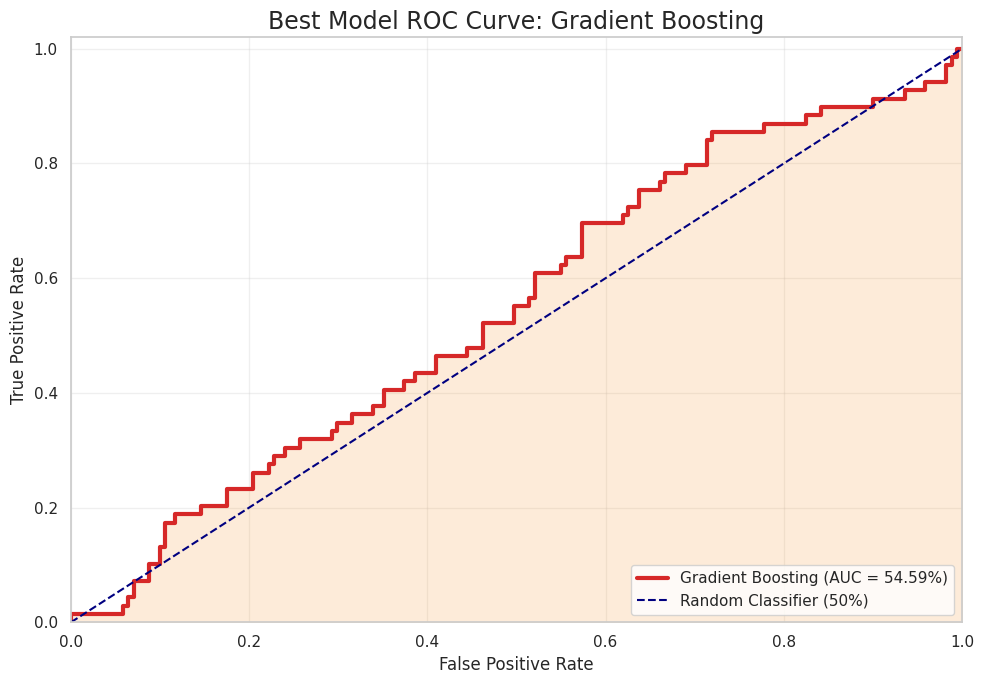


Best model by ROC AUC: Gradient Boosting
Best model ROC AUC: 54.59%

Best Model Classification Report:
              precision    recall  f1-score   support

          no       0.71      0.92      0.80       171
         yes       0.28      0.07      0.11        69

    accuracy                           0.68       240
   macro avg       0.49      0.50      0.46       240
weighted avg       0.59      0.68      0.61       240



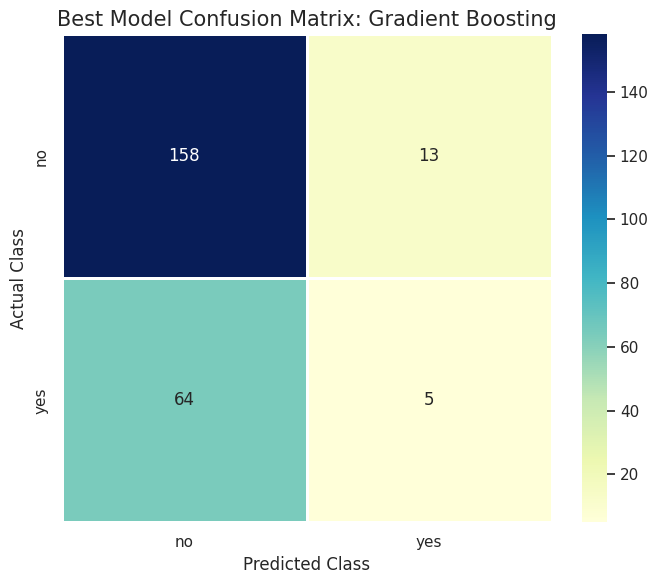


Saved model comparison to music_ml_model_comparison.csv

MACHINE LEARNING WORKFLOW COMPLETED.


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
    LabelEncoder, OneHotEncoder, StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier

# ---------------------------------------------------------------
# 1. CONFIGURATION
# ---------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "is_viral_hit"

sns.set_theme(style="whitegrid")

# Copy original merged dataset
data = df_merged.copy()
data.columns = data.columns.astype(str).str.strip()

print("=" * 80)
print("MUSIC STREAMING MACHINE LEARNING")
print("=" * 80)

print("Original dataset shape:", data.shape)

if TARGET not in data.columns:
    raise ValueError(
        f"Target '{TARGET}' not found. Available columns: "
        f"{data.columns.tolist()}"
    )

# ---------------------------------------------------------------
# 2. CLEAN DATA AND PREPARE TARGET
# ---------------------------------------------------------------

# Remove duplicate rows
data = data.drop_duplicates().copy()

# Remove rows where target is missing
data = data.dropna(subset=[TARGET]).copy()

# Normalize target values to handle common Boolean representations
target_text = data[TARGET].astype(str).str.strip().str.lower()

target_mapping = {
    "true": "yes",
    "false": "no",
    "1": "yes",
    "0": "no",
    "yes": "yes",
    "no": "no",
    "y": "yes",
    "n": "no"
}

# Normalize standard binary representations while preserving other labels
normalized_target = target_text.map(target_mapping).fillna(target_text)

data[TARGET] = normalized_target

print("\nTarget distribution:")
display(data[TARGET].value_counts().to_frame("Count"))

print("\nTarget class percentages:")
display(
    (data[TARGET].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage")
)

if data[TARGET].nunique() != 2:
    raise ValueError(
        f"ROC code below requires exactly 2 target classes. "
        f"Found {data[TARGET].nunique()} classes: "
        f"{data[TARGET].unique().tolist()}. "
        "Check the target labels or select a binary target."
    )

# Encode target labels: for example, no=0 and yes=1
label_encoder = LabelEncoder()
y = pd.Series(
    label_encoder.fit_transform(data[TARGET]),
    index=data.index,
    name=TARGET
)

print("\nTarget label encoding:")
for original, encoded in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{original} -> {encoded}")

# Positive class is encoded as 1.
positive_class_name = label_encoder.inverse_transform([1])[0]
print("\nPositive class for ROC:", positive_class_name)

# ---------------------------------------------------------------
# 3. FEATURE ENGINEERING
# ---------------------------------------------------------------

# Parse dates safely and derive useful features
if "release_date" in data.columns:
    data["release_date"] = pd.to_datetime(
        data["release_date"], errors="coerce"
    )
    data["release_year"] = data["release_date"].dt.year
    data["release_month"] = data["release_date"].dt.month

# Convert duration from milliseconds to minutes
if "duration_ms" in data.columns:
    data["duration_min"] = (
        pd.to_numeric(data["duration_ms"], errors="coerce") / 60000
    )

# ---------------------------------------------------------------
# 4. SELECT FEATURES
# ---------------------------------------------------------------

# Exclude IDs, free-text identifiers, raw dates, and variables that
# may directly reveal viral status when predicting a future hit.
#
# Remove these leakage-prone columns from predictors by default:
# - total_streams_mil
# - weeks_on_top_100
# - longevity_score
# - peak_chart_rank
#
# If your prediction is intended for a future time, these should
# not contain information from after the prediction point.

excluded_columns = [
    TARGET,
    "track_id",
    "track_title",
    "artist_name",
    "release_date",
    "total_streams_mil",
    "weeks_on_top_100",
    "longevity_score",
    "peak_chart_rank"
]

X = data.drop(
    columns=[c for c in excluded_columns if c in data.columns],
    errors="ignore"
).copy()

# Remove entirely empty and constant columns
X = X.loc[:, X.notna().any(axis=0)]

constant_columns = [
    c for c in X.columns if X[c].nunique(dropna=True) <= 1
]
X.drop(columns=constant_columns, inplace=True, errors="ignore")

# Convert Boolean columns to strings so they are handled categorically
for col in X.columns:
    if pd.api.types.is_bool_dtype(X[col]):
        X[col] = X[col].astype("string")

# Treat known categorical features as categorical, even if coded as numbers
known_categorical = [
    "genre", "musical_key", "mode", "is_explicit"
]

for col in known_categorical:
    if col in X.columns:
        X[col] = X[col].astype("string")

# Convert remaining numeric-looking object columns when appropriate
for col in X.select_dtypes(include=["object"]).columns:
    converted = pd.to_numeric(X[col], errors="coerce")
    if converted.notna().sum() >= max(1, int(0.8 * X[col].notna().sum())):
        X[col] = converted

# Separate numeric and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    c for c in X.columns if c not in numeric_features
]

if not numeric_features and not categorical_features:
    raise ValueError("No usable features remain after feature selection.")

print("\nSelected feature count:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Excluded columns:", [
    c for c in excluded_columns if c in data.columns
])

print("\nFeature preview:")
display(X.head())

# ---------------------------------------------------------------
# 5. TRAIN-TEST SPLITTING
# ---------------------------------------------------------------

# Split before fitting imputers, encoders, or scalers.
# Stratification keeps class proportions similar in both sets.

class_counts = y.value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Each target class must contain at least 2 rows for "
        "stratified train-test splitting."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

# ---------------------------------------------------------------
# 6. ENCODING AND SCALING PIPELINE
# ---------------------------------------------------------------

# LabelEncoder is used for the target.
# OneHotEncoder is appropriate for input categories because it
# does not falsely imply that categories have a numerical order.

try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", categorical_encoder)
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# ---------------------------------------------------------------
# 7. DEFINE MULTIPLE ML ALGORITHMS
# ---------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.08,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=7,
        weights="distance",
        n_jobs=-1
    )
}

# ---------------------------------------------------------------
# 8. TRAIN MODELS AND CALCULATE METRICS
# ---------------------------------------------------------------

results = []
trained_models = {}
roc_data = {}
confusion_matrices = {}

for model_name, classifier in models.items():

    print("\n" + "=" * 80)
    print("TRAINING:", model_name)
    print("=" * 80)

    # Every model gets its own preprocessing pipeline.
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    try:
        pipeline.fit(X_train, y_train)

        # Predictions on held-out test data
        y_pred = pipeline.predict(X_test)

        # Scores for ROC curve: probabilities where available,
        # otherwise decision scores from the classifier.
        if hasattr(pipeline, "predict_proba"):
            y_score = pipeline.predict_proba(X_test)[:, 1]
        elif hasattr(pipeline, "decision_function"):
            y_score = pipeline.decision_function(X_test)
        else:
            print("Skipped: model does not provide ROC scores.")
            continue

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )
        auc = roc_auc_score(y_test, y_score)

        cm = confusion_matrix(
            y_test, y_pred, labels=[0, 1]
        )

        results.append({
            "Model": model_name,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1 Score (%)": f1 * 100,
            "ROC AUC (%)": auc * 100
        })

        trained_models[model_name] = pipeline
        roc_data[model_name] = (y_test.copy(), y_score)
        confusion_matrices[model_name] = cm

        print(f"Accuracy:  {accuracy * 100:.2f}%")
        print(f"Precision: {precision * 100:.2f}%")
        print(f"Recall:    {recall * 100:.2f}%")
        print(f"F1 Score:  {f1 * 100:.2f}%")
        print(f"ROC AUC:   {auc * 100:.2f}%")

        print("\nClassification Report:")
        print(
            classification_report(
                y_test,
                y_pred,
                labels=[0, 1],
                target_names=[
                    str(label_encoder.classes_[0]),
                    str(label_encoder.classes_[1])
                ],
                zero_division=0
            )
        )

    except Exception as error:
        print(f"Model failed: {model_name}")
        print("Reason:", str(error))

if not results:
    raise RuntimeError(
        "No models trained successfully. Review the dataset and errors above."
    )

# ---------------------------------------------------------------
# 9. MODEL COMPARISON TABLE
# ---------------------------------------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="ROC AUC (%)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(results_df.round(2))

# ---------------------------------------------------------------
# 10. MODEL COMPARISON VISUALIZATION
# ---------------------------------------------------------------

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)",
    "ROC AUC (%)"
]

plot_results = results_df.set_index("Model")[metric_columns]

ax = plot_results.plot(
    kind="bar",
    figsize=(15, 7),
    colormap="tab10",
    width=0.82
)

plt.title("Machine Learning Model Comparison", fontsize=18)
plt.xlabel("ML Algorithm")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metrics", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 11. INDIVIDUAL CONFUSION MATRICES
# ---------------------------------------------------------------

for model_name, cm in confusion_matrices.items():

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=1,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"Confusion Matrix - {model_name}", fontsize=14)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------------
# 12. ROC CURVES FOR ALL MODELS
# ---------------------------------------------------------------

plt.figure(figsize=(11, 8))

for model_name, (actual, scores) in roc_data.items():

    fpr, tpr, thresholds = roc_curve(actual, scores)
    auc = roc_auc_score(actual, scores)

    plt.plot(
        fpr,
        tpr,
        linewidth=2.2,
        label=f"{model_name} (AUC = {auc * 100:.2f}%)"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Random Classifier (AUC = 50%)"
)

plt.title("ROC Curve Comparison - All ML Models", fontsize=18)
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 13. BEST MODEL ROC CURVE IN DETAIL
# ---------------------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_best, score_best = roc_data[best_model_name]

fpr, tpr, thresholds = roc_curve(y_best, score_best)
best_auc = roc_auc_score(y_best, score_best)

plt.figure(figsize=(10, 7))

plt.plot(
    fpr,
    tpr,
    color="#D62828",
    linewidth=3,
    label=f"{best_model_name} (AUC = {best_auc * 100:.2f}%)"
)

plt.fill_between(
    fpr,
    tpr,
    alpha=0.15,
    color="#F77F00"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="navy",
    label="Random Classifier (50%)"
)

plt.title(
    f"Best Model ROC Curve: {best_model_name}",
    fontsize=17
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nBest model by ROC AUC: {best_model_name}")
print(f"Best model ROC AUC: {best_auc * 100:.2f}%")

# ---------------------------------------------------------------
# 14. BEST MODEL: CLASSIFICATION REPORT
# ---------------------------------------------------------------

best_predictions = best_model.predict(X_test)

print("\nBest Model Classification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=[
            str(label_encoder.classes_[0]),
            str(label_encoder.classes_[1])
        ],
        zero_division=0
    )
)

# ---------------------------------------------------------------
# 15. BEST MODEL: CONFUSION MATRIX
# ---------------------------------------------------------------

best_cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    best_cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=1,
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Best Model Confusion Matrix: {best_model_name}", fontsize=15)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 16. SAVE MODEL COMPARISON RESULTS
# ---------------------------------------------------------------

results_df.to_csv(
    "music_ml_model_comparison.csv",
    index=False
)

print("\nSaved model comparison to music_ml_model_comparison.csv")
print("\nMACHINE LEARNING WORKFLOW COMPLETED.")

